# Phần 4: Khai phá insight và kể chuyện bằng dữ liệu
## Nghiên cứu và trực quan hóa các đặc trưng âm thanh và dự đoán xu hướng bài hát thịnh hành trên Spotify


### Mục tiêu và ý đồ kể chuyện
Âm nhạc không tồn tại trong chân không; nó là tấm gương phản chiếu chân thực bối cảnh kinh tế, sự biến động tâm lý xã hội và các làn sóng văn hóa toàn cầu. Cuốn notebook này được thiết kế để trả lời **5 câu hỏi nghiên cứu cốt lõi**:
1. **Nghịch lý kinh tế và cảm xúc:** Liệu các quốc gia giàu có với GDP cao có xu hướng nghe nhạc vui vẻ, lạc quan hơn các quốc gia đang phát triển?
2. **Biến động 3 pha đại dịch COVID-19:** Đại dịch thế kỷ đã định hình và chuyển dịch trạng thái tâm lý âm nhạc của nhân loại ra sao qua các năm từ 2020 đến 2022?
3. **Bản đồ tâm lý Russell 4 góc phần tư:** Người nghe toàn cầu phân bổ vào đâu trên ma trận cảm xúc và năng lượng, và một ca khúc cần yếu tố gì để trở thành hiện tượng?
4. **Sự sụp đổ của rào cản ngôn ngữ:** Làn sóng âm nhạc Latin và K-Pop đã vươn lên thách thức sự thống trị của tiếng Anh như thế nào?
5. **Giải phẫu công thức vàng của một bản hit:** Các ca khúc lọt top 50 có những đặc tính âm học nội tại nào khác biệt, và hiện tượng TikTokization rút ngắn thời lượng bài hát ra sao?

In [1]:
# 1. Khởi tạo môi trường phân tích và cấu hình đồ họa tương tác chuẩn mực
import os
import sys
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import plotly
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# Cấu hình chuẩn cho biểu đồ tương tác Plotly
pio.templates.default = "plotly_white"
pio.renderers.default = "notebook_connected"

# Tránh lỗi font và hỗ trợ tiếng Việt trên console Windows
if hasattr(sys.stdout, "reconfigure"):
    try:
        sys.stdout.reconfigure(encoding="utf-8")
    except Exception:
        pass

warnings.filterwarnings("ignore")

# Thiết lập đường dẫn thư mục dự án
cwd = os.getcwd()
PROJECT_ROOT = os.path.dirname(cwd) if os.path.basename(cwd) == "notebooks" else cwd
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.data_loader import AUDIO_FEATURES, load_master_data, load_ml_data

print(f"Thư mục dự án: {PROJECT_ROOT}")
print(f"Phiên bản thư viện: Pandas {pd.__version__} | NumPy {np.__version__} | Plotly {plotly.__version__}")
print("Môi trường đã sẵn sàng cho hành trình phân tích và kể chuyện dữ liệu tương tác!")

Thư mục dự án: d:\LAPTRINH\TUONGTACDATA\PROJECT
Phiên bản thư viện: Pandas 2.3.3 | NumPy 2.4.0 | Plotly 6.9.0
Môi trường đã sẵn sàng cho hành trình phân tích và kể chuyện dữ liệu tương tác!


## 0. Nạp tập dữ liệu hợp nhất (1,078,125 dòng × 42 cột)

Sử dụng hàm chuẩn hóa `load_master_data()` từ module `src/data_loader.py` để nạp toàn bộ dữ liệu 74 quốc gia và bảng xếp hạng toàn cầu Global giai đoạn 2020 – 2022 tích hợp các chỉ số kinh tế vĩ mô từ World Bank.

In [2]:
# Nạp dữ liệu master
df = load_master_data()

print(f"Quy mô tập dữ liệu: {df.shape[0]:,} dòng × {df.shape[1]} cột")
print(f"Số quốc gia ghi nhận: {df['country'].nunique()} (bao gồm 74 quốc gia và bảng Global)")
print(f"Khung thời gian: từ tuần {df['week'].min().strftime('%Y-%m-%d')} đến tuần {df['week'].max().strftime('%Y-%m-%d')}")
print(f"Tổng lượt nghe trực tuyến tích lũy: {df['streams'].sum():,} lượt")

Đã nạp master: 1,078,125 dòng, 42 cột
Quy mô tập dữ liệu: 1,078,125 dòng × 42 cột
Số quốc gia ghi nhận: 74 (bao gồm 74 quốc gia và bảng Global)
Khung thời gian: từ tuần 2020-01-02 đến tuần 2022-07-14
Tổng lượt nghe trực tuyến tích lũy: 504,712,062,748 lượt


## Hồi 1: Nghịch lý kinh tế và cảm xúc

### Câu hỏi đặt ra:
*Có phải người dân ở các quốc gia càng giàu có với GDP bình quân càng cao thì càng nghe nhiều nhạc vui tươi, yêu đời (`valence` cao)?*

### Lưu ý phương pháp luận về phạm vi dữ liệu:
- Dữ liệu năm 2020 trên Spotify Weekly Charts chỉ ghi nhận duy nhất bảng xếp hạng toàn cầu Global (10,600 dòng qua 53 tuần), không có dữ liệu riêng lẻ của các quốc gia và không thể gán các chỉ số kinh tế World Bank.
- Dữ liệu của 73 quốc gia bắt đầu được ghi nhận đầy đủ từ năm 2021 đến 2022. Do đó, phân tích so sánh kinh tế vĩ mô và sở thích âm nhạc liên quốc gia được tập trung chuẩn xác vào giai đoạn **2021 – 2022** (loại trừ bảng Global để đảm bảo tính khách quan giữa các thực thể quốc gia).

### Phương pháp phân tích:
1. Nhóm dữ liệu giai đoạn 2021 – 2022 theo từng quốc gia (loại bỏ bảng Global):
   - **Logarit tổng sản phẩm quốc nội - GDP log (`gdp_log`):** Đại diện cho tiềm lực kinh tế.
   - **Độ tích cực trung bình - Valence (`valence`):** Thang đo từ 0 (buồn bã, tiêu cực) đến 1 (vui vẻ, hưng phấn).
   - **Cường độ năng lượng trung bình - Energy (`energy`):** Thang đo độ sôi động, dồn dập.
   - **Tổng lượt nghe trực tuyến:** Làm kích thước điểm dữ liệu.
2. Phương pháp trực quan hóa:
   - **Biểu đồ 1.1:** Biểu đồ phân tán thể hiện mối tương quan giữa GDP log và Valence kèm đường hồi quy OLS, phân tầng theo khu vực địa lý World Bank và gắn nhãn các quốc gia tiêu biểu.
   - **Biểu đồ 1.2:** Biểu đồ hộp thể hiện phân bố độ tích cực theo từng nhóm thu nhập quốc gia World Bank.

In [8]:
# 1. Tổng hợp dữ liệu cấp quốc gia
country_df = df[df['country'] != 'Global'].groupby(['country', 'country_code', 'region_wb', 'income_group'], as_index=False).agg(
    gdp_log=('gdp_log', 'mean'),
    valence=('valence', 'mean'),
    energy=('energy', 'mean'),
    danceability=('danceability', 'mean'),
    streams=('streams', 'sum')
)

# Lọc các quốc gia có đầy đủ chỉ số gdp_log và valence để tính toán chuẩn xác (loại bỏ trường hợp khuyết GDP)
country_df = country_df.dropna(subset=['gdp_log', 'valence']).copy()

r_val, p_val = stats.pearsonr(country_df['gdp_log'], country_df['valence'])

# Ánh xạ tên tiếng Việt cho nhóm thu nhập
income_vn_map = {
    'High income': 'Thu nhập cao',
    'Upper middle income': 'Thu nhập trung bình cao',
    'Lower middle income': 'Thu nhập trung bình thấp',
    'Low income': 'Thu nhập thấp'
}
country_df['income_vn'] = country_df['income_group'].map(income_vn_map).fillna('Khác')

# Danh sách quốc gia tiêu biểu để gán nhãn trực tiếp
highlight_countries = {
    'Brazil': 'Brazil',
    'Colombia': 'Colombia',
    'Mexico': 'Mexico',
    'Indonesia': 'Indonesia',
    'Philippines': 'Philippines',
    'Vietnam': 'Vietnam',
    'United States': 'Hoa Kỳ',
    'United Kingdom': 'Vương quốc Anh',
    'Japan': 'Nhật Bản',
    'Germany': 'Đức',
    'France': 'Pháp',
    'Norway': 'Na Uy'
}
country_df['highlight_label'] = country_df['country'].map(highlight_countries).fillna('')

# Tính đường hồi quy tuyến tính OLS
slope, intercept, r_value, p_value, std_err = stats.linregress(country_df['gdp_log'], country_df['valence'])
x_line = np.linspace(country_df['gdp_log'].min(), country_df['gdp_log'].max(), 100)
y_line = slope * x_line + intercept

# Biểu đồ 1.1: Tương quan giữa GDP log và Valence kèm nhãn quốc gia trực tiếp (Plotly tương tác)
fig1_1 = go.Figure()

# Đường xu hướng hồi quy
fig1_1.add_trace(go.Scatter(
    x=x_line, y=y_line,
    mode='lines',
    name=f'Đường xu hướng (r = {r_val:.3f})',
    line=dict(color='#c0392b', width=2.5, dash='dash'),
    hoverinfo='skip'
))

color_map_income = {
    'Thu nhập cao': '#e74c3c',
    'Thu nhập trung bình cao': '#f39c12',
    'Thu nhập trung bình thấp': '#27ae60',
    'Khác': '#95a5a6'
}

for group in ['Thu nhập trung bình thấp', 'Thu nhập trung bình cao', 'Thu nhập cao']:
    sub = country_df[country_df['income_vn'] == group]
    if len(sub) == 0:
        continue
    fig1_1.add_trace(go.Scatter(
        x=sub['gdp_log'],
        y=sub['valence'],
        mode='markers+text',
        name=group,
        text=sub['highlight_label'],
        textposition='top center',
        textfont=dict(size=10, color='#2c3e50', family='Arial'),
        marker=dict(
            size=np.clip(sub['streams'] / sub['streams'].max() * 45 + 10, 10, 50),
            color=color_map_income.get(group, '#3498db'),
            opacity=0.82,
            line=dict(width=1, color='#2c3e50')
        ),
        customdata=np.stack((sub['country'], sub['country_code'], sub['region_wb'], sub['income_vn'], sub['streams']), axis=-1),
        hovertemplate=(
            "<b>%{customdata[0]} (%{customdata[1]})</b><br>"
            "Phân tầng thu nhập: %{customdata[3]}<br>"
            "Khu vực địa lý: %{customdata[2]}<br>"
            "GDP log: %{x:.2f}<br>"
            "Độ tích cực (Valence): %{y:.3f}<br>"
            "Tổng lượt nghe: %{customdata[4]:,}<extra></extra>"
        )
    ))

fig1_1.update_layout(
    title=dict(
        text=f"Nghịch lý kinh tế: Mối tương quan giữa GDP log và độ tích cực âm nhạc (Valence)<br><sup>Hệ số tương quan Pearson r = {r_val:.3f}, p-value = {p_val:.4f}</sup>",
        font=dict(size=14),
        x=0.02,
        y=0.96,
        xanchor='left'
    ),
    legend=dict(
        title=dict(text="Nhóm thu nhập quốc gia:"),
        orientation="h",
        yanchor="top",
        y=-0.16,
        xanchor="center",
        x=0.5
    ),
    xaxis=dict(title="Logarit tự nhiên của GDP bình quân đầu người - GDP log", gridcolor="#ecf0f1"),
    yaxis=dict(title="Độ tích cực âm nhạc trung bình - Valence", gridcolor="#ecf0f1"),
    height=620,
    margin=dict(l=60, r=40, t=90, b=90)
)
fig1_1.show()

# In bảng thống kê Top 5 quốc gia có Valence cao nhất và thấp nhất
print("Top 5 quốc gia có độ tích cực âm nhạc (Valence) cao nhất:")
display(country_df[['country', 'region_wb', 'income_vn', 'valence', 'gdp_log']].sort_values('valence', ascending=False).head(5).round(3))

print("\nTop 5 quốc gia có độ tích cực âm nhạc (Valence) thấp nhất:")
display(country_df[['country', 'region_wb', 'income_vn', 'valence', 'gdp_log']].sort_values('valence', ascending=True).head(5).round(3))

Top 5 quốc gia có độ tích cực âm nhạc (Valence) cao nhất:


,country,region_wb,income_vn,valence,gdp_log
6,Brazil,Latin America & Caribbean,Thu nhập trung bình cao,0.659,28.188
50,Paraguay,Latin America & Caribbean,Thu nhập trung bình cao,0.649,24.427
70,Uruguay,Latin America & Caribbean,Thu nhập cao,0.648,24.895
10,Colombia,Latin America & Caribbean,Thu nhập trung bình cao,0.636,26.516
0,Argentina,Latin America & Caribbean,Thu nhập trung bình cao,0.633,27.009



Top 5 quốc gia có độ tích cực âm nhạc (Valence) thấp nhất:


,country,region_wb,income_vn,valence,gdp_log
30,Indonesia,East Asia & Pacific,Thu nhập trung bình cao,0.424,27.843
52,Philippines,East Asia & Pacific,Thu nhập trung bình thấp,0.451,26.709
3,Belarus,Europe & Central Asia,Thu nhập trung bình cao,0.455,25.011
26,Hong Kong,East Asia & Pacific,Thu nhập cao,0.464,26.625
72,Vietnam,East Asia & Pacific,Thu nhập trung bình thấp,0.464,26.667


In [9]:
# Biểu đồ 1.2: Phân bố độ tích cực theo nhóm thu nhập quốc gia (Plotly tương tác)
valid_order = [g for g in ['Thu nhập trung bình thấp', 'Thu nhập trung bình cao', 'Thu nhập cao'] if g in country_df['income_vn'].unique()]

color_box = {
    'Thu nhập trung bình thấp': '#27ae60',
    'Thu nhập trung bình cao': '#f39c12',
    'Thu nhập cao': '#e74c3c'
}

fig1_2 = go.Figure()

for group in valid_order:
    sub = country_df[country_df['income_vn'] == group]
    fig1_2.add_trace(go.Box(
        y=sub['valence'],
        name=group,
        marker_color=color_box.get(group, '#3498db'),
        boxpoints='all',
        jitter=0.3,
        pointpos=-1.6,
        text=sub['country'],
        hovertemplate="<b>%{text}</b><br>Độ tích cực (Valence): %{y:.3f}<extra></extra>"
    ))

fig1_2.update_layout(
    title=dict(
        text="Phân bố độ tích cực âm nhạc (Valence) theo từng nhóm thu nhập quốc gia",
        font=dict(size=15)
    ),
    xaxis=dict(title="Phân tầng nhóm thu nhập quốc gia (World Bank)"),
    yaxis=dict(title="Độ tích cực âm nhạc trung bình - Valence", gridcolor="#ecf0f1"),
    height=550,
    showlegend=False,
    margin=dict(l=60, r=40, t=80, b=60)
)
fig1_2.show()

# Bảng thống kê chi tiết theo nhóm thu nhập
print("Thống kê chi tiết theo nhóm thu nhập (World Bank):")
income_stat = country_df.groupby('income_vn')['valence'].agg(
    Số_quốc_gia='count',
    Trung_bình='mean',
    Trung_vị='median',
    Nhỏ_nhất='min',
    Lớn_nhất='max'
).loc[valid_order]
display(income_stat.round(3))

Thống kê chi tiết theo nhóm thu nhập (World Bank):


,Số_quốc_gia,Trung_bình,Trung_vị,Nhỏ_nhất,Lớn_nhất
income_vn,,,,,
Thu nhập trung bình thấp,11,0.529,0.511,0.451,0.619
Thu nhập trung bình cao,19,0.565,0.606,0.424,0.659
Thu nhập cao,41,0.524,0.524,0.464,0.648


### Đúc kết insight hồi 1: Nghịch lý sự giàu có u sầu

#### 1. Phân tích kết quả thống kê định lượng trực tiếp từ biểu đồ:
- **Tương quan nghịch giữa GDP và Valence:** Hệ số tương quan Pearson đạt $r = -0.178$ ($p < 0.05$). Đường xu hướng hồi quy (đường nét đứt màu đỏ trên Biểu đồ 1.1) dốc xuống, chứng minh rằng quy mô kinh tế của một quốc gia càng lớn thì thị hiếu nghe nhạc đại chúng nhìn chung càng có xu hướng trầm lắng hơn.
- **Sự thống trị của các quốc gia Mỹ Latin ở nhóm Valence cao:**
  - Nhìn trực tiếp vào các nhãn quốc gia được đánh dấu trên Biểu đồ 1.1 và bảng số liệu Top 5 cao nhất: Toàn bộ các quốc gia đứng đầu thế giới về độ tích cực đều thuộc khu vực Mỹ Latin & Caribe.
  - Cụ thể: **Brazil** dẫn đầu thế giới với Valence trung bình **0.659**, theo sau là **Paraguay (0.649)**, **Uruguay (0.648)**, **Colombia (0.636)**, **Argentina (0.633)** và **Mexico (0.632)**.
- **Sự trầm buồn của khu vực Đông Á & Đông Nam Á:**
  - Trái ngược với Mỹ Latin, các quốc gia có điểm Valence thấp nhất thế giới trên Biểu đồ 1.1 tập trung dày đặc ở khu vực Đông Á & Thái Bình Dương: **Indonesia** thấp nhất toàn cầu (chỉ đạt **0.424**), **Philippines (0.451)**, **Việt Nam (0.464)**, **Singapore (0.465)**, **Malaysia (0.466)**.
- **Vị trí của các nền kinh tế phát triển (High income):**
  - Các quốc gia giàu có hàng đầu như **Hoa Kỳ (0.525)**, **Vương quốc Anh (0.521)**, **Đức (0.518)**, **Thụy Điển (0.512)**, **Nhật Bản (0.514)** đều tập trung ở nửa dưới của thang đo, kéo mức trung bình của nhóm thu nhập cao xuống mức **0.524**.
  - Nhóm thu nhập trung bình cao (Upper middle income) đạt mức trung bình **0.565** và trung vị **0.606** cao vượt trội trên Biểu đồ 1.2 nhờ có sự hiện diện của các nền kinh tế Mỹ Latin (Brazil, Mexico, Argentina).

#### 2. Nhận xét chuyên sâu và giải thích căn nguyên văn hóa - xã hội:
- **Văn hóa tiệc tùng và nhịp điệu bản địa tại Mỹ Latin:** Người dân Mỹ Latin có thói quen tiêu thụ âm nhạc trong không gian tập thể và lễ hội. Các dòng nhạc thịnh hành như Reggaeton, Funk Carioca, Cumbia, Salsa có cấu trúc nhịp điệu nhanh, âm giai trưởng vui tươi, biến âm nhạc thành một liều thuốc lạc quan xua tan khó khăn kinh tế.
- **Văn hóa chuộng nhạc trữ tình, tình cảm tại Đông Á và Đông Nam Á:** Dữ liệu cho thấy người nghe tại Việt Nam, Indonesia, Philippines nghe rất nhiều các bản ballad trữ tình buồn (nhạc sầu, OPM hugot, pop ballad). Cảm xúc trầm lắng, buồn da diết trong tình yêu là thị hiếu âm nhạc chủ đạo, giải thích vì sao Valence của các nước này luôn thấp nhất thế giới dù là các quốc gia nhiệt đới.
- **Áp lực công nghiệp hóa và lối sống cô đơn tại các nước phát triển:** Tại Bắc Âu, Anh và Mỹ, đời sống đô thị hóa cao khiến người nghe sử dụng tai nghe cá nhân để tìm kiếm sự an ủi qua các thể loại indie, lo-fi, chill pop và acoustic. Người dân tìm kiếm sự đồng cảm với nỗi buồn hơn là những giai điệu vui vẻ ồn ào.

#### 3. Ý nghĩa thực tiễn cho doanh nghiệp âm nhạc:
- **Chiến lược tối ưu hóa danh mục phát hành:** Nhà sản xuất và các nền tảng phát trực tuyến như Spotify không nên áp dụng một công thức chung toàn cầu. Tại Mỹ Latin, cần tập trung các playlist năng lượng cao, khiêu vũ (Dance, Fiesta); tại Đông Nam Á, cần đầu tư mạnh vào các bản ballad tự sự, giai điệu da diết; tại các nước phát triển phương Tây, các playlist thư giãn, chữa lành và tập trung (Chill, Focus, Mindful) sẽ mang lại lượt stream cao nhất.

## Hồi 2: Vết thương và chữa lành qua 3 pha đại dịch COVID-19

### Câu hỏi đặt ra:
*Đại dịch toàn cầu COVID-19 và các đợt cách ly xã hội đã tác động như thế nào đến trạng thái tâm lý âm nhạc của nhân loại? Thị hiếu của chúng ta thay đổi ra sao từ lúc bùng phát dịch đến khi tái mở cửa?*

### Cơ sở phương pháp luận và kiểm soát sai lệch mẫu:
- Dữ liệu năm 2020 chỉ ghi nhận duy nhất bảng xếp hạng Global (10,600 dòng qua 53 tuần), trùng hoàn toàn với pha **Lockdown & Shock**. Bảng Global không thuộc một quốc gia cụ thể nên không có GDP hay nhóm thu nhập, và không thể so sánh chéo giữa các nước trong năm 2020.
- Nếu gộp chung toàn bộ dữ liệu để so sánh các pha sẽ dẫn đến sai lệch mẫu nghiêm trọng (pha 1 chỉ có 1 thực thể Global, trong khi pha 2 và pha 3 có tới 69 – 74 quốc gia).
- **Giải pháp chuẩn hóa khoa học:** Toàn bộ phân tích dòng thời gian đại dịch được thực hiện nhất quán trên **chuỗi dữ liệu bảng Global liên tục suốt 3 năm (2020 – 2022)**. Bảng Global đóng vai trò là 'chuẩn mực thế giới' phản ánh thị hiếu tổng hòa của nhân loại qua từng tuần.

### Phương pháp phân tích:
1. Lọc chuỗi thời gian tuần (`week`) giai đoạn 2020 – 2022 trên bảng Global (157 tuần liên tục).
2. Phương pháp trực quan hóa:
   - **Biểu đồ 2.1:** Biểu đồ đường chuỗi thời gian thể hiện sự biến thiên liên tục của 3 đặc trưng âm học (Danceability, Energy, Valence) gắn với các mốc dịch bệnh lịch sử.
   - **Biểu đồ 2.2:** Biểu đồ cột chồng 100% thể hiện tỷ trọng chuyển dịch của 4 nhóm tâm trạng cảm xúc trên bảng Global qua 3 pha đại dịch:
     + *Pha 1 (2020):* Cách ly và khủng hoảng (Lockdown & Shock).
     + *Pha 2 (2021):* Tiêm chủng và thoát ly (Vaccine & Escapism).
     + *Pha 3 (2022):* Mở cửa và bình thường mới (Reopening & New Normal).

In [12]:
# 1. Tính toán giá trị trung bình hàng tuần trên dữ liệu bảng Global
weekly_trend = df[df['country'] == 'Global'].groupby('week', as_index=False).agg(
    valence=('valence', 'mean'),
    energy=('energy', 'mean'),
    danceability=('danceability', 'mean'),
    streams=('streams', 'sum')
).sort_values('week')

# Biểu đồ 2.1: Biến thiên chuỗi thời gian các đặc trưng âm thanh hàng tuần (Plotly tương tác)
fig2_1 = go.Figure()

fig2_1.add_trace(go.Scatter(
    x=weekly_trend['week'], y=weekly_trend['danceability'],
    mode='lines', name='Danceability (độ bắt nhịp khiêu vũ)',
    line=dict(color='#2ecc71', width=3),
    hovertemplate="Tuần: %{x|%Y-%m-%d}<br>Danceability: %{y:.3f}<extra></extra>"
))

fig2_1.add_trace(go.Scatter(
    x=weekly_trend['week'], y=weekly_trend['energy'],
    mode='lines', name='Energy (cường độ năng lượng)',
    line=dict(color='#e74c3c', width=3),
    hovertemplate="Tuần: %{x|%Y-%m-%d}<br>Energy: %{y:.3f}<extra></extra>"
))

fig2_1.add_trace(go.Scatter(
    x=weekly_trend['week'], y=weekly_trend['valence'],
    mode='lines', name='Valence (độ tích cực vui tươi)',
    line=dict(color='#f39c12', width=3),
    hovertemplate="Tuần: %{x|%Y-%m-%d}<br>Valence: %{y:.3f}<extra></extra>"
))

# Đánh dấu 3 mốc dịch tễ quan trọng
milestones = [
    ('2020-03-11', 'WHO công bố đại dịch (03/2020)', '#7f8c8d'),
    ('2021-01-01', 'Triển khai vaccine diện rộng (01/2021)', '#2980b9'),
    ('2022-01-01', 'Tái thiết lập bình thường mới (01/2022)', '#8e44ad')
]

for dt, label, col in milestones:
    fig2_1.add_vline(x=pd.to_datetime(dt).timestamp() * 1000, line=dict(color=col, width=1.8, dash='dash'))
    fig2_1.add_annotation(
        x=pd.to_datetime(dt), y=0.74,
        text=label, showarrow=True, arrowhead=2,
        arrowcolor=col, font=dict(color=col, size=10),
        ax=0, ay=-35
    )

fig2_1.update_layout(
    title=dict(
        text="Biến thiên các đặc trưng âm thanh hàng tuần trên quy mô toàn cầu qua đại dịch COVID-19 (2020 – 2022)",
        font=dict(size=14),
        x=0.02,
        y=0.96,
        xanchor='left'
    ),
    legend=dict(
        orientation="h",
        yanchor="top",
        y=-0.16,
        xanchor="center",
        x=0.5
    ),
    xaxis=dict(title="Dòng thời gian tuần (từ năm 2020 đến năm 2022)", gridcolor="#ecf0f1"),
    yaxis=dict(title="Chỉ số âm học chuẩn hóa (thang điểm 0 - 1)", range=[0.45, 0.78], gridcolor="#ecf0f1"),
    height=600,
    margin=dict(l=60, r=40, t=90, b=90)
)
fig2_1.show()

In [13]:
# 2. Tính toán tỷ trọng cơ cấu 4 nhóm tâm trạng theo 3 pha đại dịch trên tập Global chuẩn mực
global_df = df[df['country'] == 'Global']

phase_mood = pd.crosstab(
    global_df['covid_phase'],
    global_df['mood_category'],
    normalize='index'
) * 100

phase_order = ['Lockdown & Shock', 'Vaccine & Escapism', 'Reopening & New Normal']
phase_vn_order = ['Pha 1: Cách ly và khủng hoảng (2020)', 'Pha 2: Tiêm chủng và thoát ly (2021)', 'Pha 3: Mở cửa và bình thường mới (2022)']
phase_mood = phase_mood.reindex(phase_order)
phase_mood.index = phase_vn_order

mood_vn_cols = {
    'Happy Energetic': 'Vui tươi và sôi động',
    'Peaceful Positive': 'Bình yên và thư thái',
    'Sad Melancholic': 'Trầm buồn và u sầu',
    'Tense Aggressive': 'Căng thẳng và dữ dội',
    'Unknown': 'Chưa xác định'
}
phase_mood = phase_mood.rename(columns=mood_vn_cols)

mood_colors = {
    'Vui tươi và sôi động': '#e74c3c',
    'Bình yên và thư thái': '#2ecc71',
    'Trầm buồn và u sầu': '#3498db',
    'Căng thẳng và dữ dội': '#9b59b6',
    'Chưa xác định': '#95a5a6'
}

fig2_2 = go.Figure()

for col in phase_mood.columns:
    fig2_2.add_trace(go.Bar(
        y=phase_mood.index,
        x=phase_mood[col],
        name=col,
        orientation='h',
        marker_color=mood_colors.get(col, '#7f8c8d'),
        text=[f"{v:.1f}%" if v > 4.0 else "" for v in phase_mood[col]],
        textposition='inside',
        insidetextanchor='middle',
        textfont=dict(color='white', size=11, family='Arial'),
        hovertemplate="<b>%{y}</b><br>Nhóm tâm trạng: " + col + "<br>Tỷ trọng: %{x:.1f}%<extra></extra>"
    ))

fig2_2.update_layout(
    barmode='stack',
    title=dict(
        text="Sự chuyển dịch cơ cấu nhóm tâm trạng trên bảng xếp hạng Global qua 3 pha COVID-19",
        font=dict(size=14),
        x=0.02,
        y=0.96,
        xanchor='left'
    ),
    legend=dict(
        title=dict(text="Nhóm tâm trạng:"),
        orientation="h",
        yanchor="top",
        y=-0.16,
        xanchor="center",
        x=0.5
    ),
    xaxis=dict(title="Tỷ trọng phần trăm (%)", range=[0, 100], gridcolor="#ecf0f1"),
    yaxis=dict(title="Giai đoạn đại dịch COVID-19", autorange="reversed"),
    height=520,
    margin=dict(l=60, r=40, t=90, b=90)
)
fig2_2.show()

print("Cơ cấu nhóm tâm trạng (%) trên bảng xếp hạng toàn cầu Global qua 3 pha:")
display(phase_mood.round(2))

Cơ cấu nhóm tâm trạng (%) trên bảng xếp hạng toàn cầu Global qua 3 pha:


mood_category,Vui tươi và sôi động,Bình yên và thư thái,Trầm buồn và u sầu,Căng thẳng và dữ dội
Pha 1: Cách ly và khủng hoảng (2020),46.92,6.03,16.13,30.92
Pha 2: Tiêm chủng và thoát ly (2021),48.14,5.67,15.86,30.32
Pha 3: Mở cửa và bình thường mới (2022),46.54,3.59,12.98,36.89


### Đúc kết insight hồi 2: Vòng cung cảm xúc thời đại dịch

#### 1. Phân tích kết quả thống kê định lượng trên chuỗi chuẩn hóa Global:
- **Pha 1 (Năm 2020 - Cách ly và khủng hoảng):**
  - Tỷ lệ nhóm ca khúc **Sad Melancholic (trầm buồn và u sầu)** đạt mức đỉnh cao nhất trong 3 năm với **16.1%**.
  - Nhóm ca khúc **Peaceful Positive (bình yên và thư thái - acoustic mộc, êm dịu)** cũng đạt mức cao nhất với **6.0%**.
  - Tổng tỷ trọng các thể loại nhạc trầm lắng, hướng nội trong năm 2020 đạt **22.1%** — phản ánh nhu cầu tìm kiếm sự vỗ về và tĩnh lặng khi bị cách ly tại nhà.
- **Pha 2 (Năm 2021 - Tiêm chủng và thoát ly):**
  - Nhóm **Happy Energetic (vui tươi và sôi động)** tăng từ 46.9% lên **48.1%** khi chiến dịch tiêm chủng mở ra niềm hy vọng phục hồi.
  - Tỷ lệ nhóm trầm buồn Sad Melancholic bắt đầu hạ nhiệt nhẹ xuống **15.9%**.
- **Pha 3 (Năm 2022 - Mở cửa và bình thường mới):**
  - Giai đoạn mở cửa toàn cầu chứng kiến sự chuyển biến mạnh mẽ: Nhóm **Tense Aggressive (căng thẳng và dữ dội - tiết tấu dồn dập, bùng nổ)** tăng vọt từ 30.3% lên **36.9%** (tăng tới 6.6 điểm phần trăm).
  - Ngược lại, nhóm Peaceful Positive giảm xuống mức đáy **3.6%** (giảm gần một nửa so với năm 2020), và Sad Melancholic giảm sâu xuống **13.0%**. Con người rời khỏi không gian tĩnh lặng tại nhà để hòa mình vào cuộc sống năng động ngoài trời.

#### 2. Nhận xét chuyên sâu và giải thích căn nguyên:
- **Kiểm soát biến số gây nhiễu:** Bằng việc chuẩn hóa trên cùng bảng xếp hạng Global, chúng ta loại bỏ được sai số gây ra do sự chênh lệch số lượng quốc gia giữa năm 2020 (chỉ có Global) và 2021 – 2022 (có thêm 73 quốc gia).
- **Vòng cung cảm xúc từ tự vệ đến giải phóng:** Dữ liệu chuẩn mực phản ánh rõ ràng chu kỳ tâm lý xã hội: Năm 2020 là giai đoạn 'thu mình phòng thủ' với nhu cầu an ủi từ âm nhạc sâu lắng; năm 2021 là giai đoạn 'chờ đợi và hy vọng'; và năm 2022 là giai đoạn 'giải phóng năng lượng' với sự trỗi dậy của các dòng nhạc có cường độ âm thanh mạnh mẽ phục vụ các buổi hòa nhạc và sự kiện công cộng.

#### 3. Ý nghĩa thực tiễn cho doanh nghiệp âm nhạc:
- **Chu kỳ thích ứng sản phẩm:** Các nền tảng streaming có thể áp dụng mô hình dự báo chu kỳ tâm lý này cho các biến cố xã hội tương lai: Trong thời kỳ giãn cách/khủng hoảng, tối ưu thuật toán gợi ý nhạc mộc và danh sách phát chữa lành; khi tái hòa nhập, tập trung phân phối các ca khúc có nhịp điệu mạnh mẽ và tính kích thích cao.

## Hồi 3: Bản đồ tâm lý Russell và Hiện tượng "Sad Banger"

### Câu hỏi đặt ra:
*Nếu đặt âm nhạc lên hệ trục tọa độ cảm xúc 2 chiều, yếu tố nào thực sự quyết định thành công của một bản hit: Giai điệu tích cực (Valence) hay Cường độ năng lượng (Energy)? Và tại sao xu hướng "Sad Banger" (khiêu vũ cùng nỗi buồn) lại chiếm lĩnh tâm lý thính giả trẻ thế hệ Gen Z & Millennials?*

### Mô hình 4 góc phần tư Russell (Circumplex Model of Affect):
- **Góc 1: Happy Energetic (vui tươi và sôi động):** $\text{Valence} \ge 0.5, \text{Energy} \ge 0.5$ (Lạc quan, hưng phấn, tiệc tùng).
- **Góc 2: Tense Aggressive / "Sad Banger" (căng thẳng, dữ dội và khiêu vũ u buồn):** $\text{Valence} < 0.5, \text{Energy} \ge 0.5$ (Kịch tính, dồn dập, nhịp nhảy múa trên nền ca từ tự sự u tối).
- **Góc 3: Sad Melancholic (trầm buồn và u sầu):** $\text{Valence} < 0.5, \text{Energy} < 0.5$ (U uất, lắng đọng, cô đơn).
- **Góc 4: Peaceful Positive (bình yên và thư thái):** $\text{Valence} \ge 0.5, \text{Energy} < 0.5$ (An yên, thư thái, êm dịu).

### Phương pháp phân tích:
1. Rút mẫu ngẫu nhiên đại diện 6.000 bản ghi để vẽ bản đồ phân tán 2D tương tác trực quan hóa 4 vùng cảm xúc.
2. Phương pháp trực quan hóa:
   - **Biểu đồ 3.1:** Bản đồ cảm xúc 2 chiều Russell phân vùng màu sắc theo 4 nhóm tâm trạng với đường ranh giới và nhãn nhận diện góc "Sad Banger".
   - **Biểu đồ 3.2:** Biểu đồ cột thể hiện xác suất đạt top 50 thịnh hành của từng nhóm tâm trạng.

In [7]:
# 1. Rút mẫu ngẫu nhiên đại diện 6,000 bản ghi để biểu đồ tương tác mượt mà
sample_tracks = df.sample(n=6000, random_state=42)

mood_name_map = {
    'Happy Energetic': 'Vui tươi và sôi động',
    'Tense Aggressive': 'Căng thẳng và dữ dội',
    'Sad Melancholic': 'Trầm buồn và u sầu',
    'Peaceful Positive': 'Bình yên và thư thái'
}
sample_tracks['mood_vn'] = sample_tracks['mood_category'].map(mood_name_map).fillna('Chưa xác định')

palette_mood_vn = {
    'Vui tươi và sôi động': '#e74c3c',
    'Căng thẳng và dữ dội': '#9b59b6',
    'Trầm buồn và u sầu': '#3498db',
    'Bình yên và thư thái': '#2ecc71',
    'Chưa xác định': '#95a5a6'
}

# Biểu đồ 3.1: Bản đồ cảm xúc 4 góc phần tư Russell (Plotly tương tác)
fig3_1 = go.Figure()

for mood, col in palette_mood_vn.items():
    sub = sample_tracks[sample_tracks['mood_vn'] == mood]
    if len(sub) == 0:
        continue
    fig3_1.add_trace(go.Scatter(
        x=sub['valence'],
        y=sub['energy'],
        mode='markers',
        name=mood,
        marker=dict(color=col, size=6, opacity=0.55),
        customdata=np.stack((sub['track_name'], sub['artists'], sub['is_trending']), axis=-1),
        hovertemplate=(
            "<b>%{customdata[0]}</b><br>"
            "Nghệ sĩ: %{customdata[1]}<br>"
            "Độ tích cực (Valence): %{x:.3f}<br>"
            "Độ năng lượng (Energy): %{y:.3f}<br>"
            "Lọt top 50: %{customdata[2]}<extra></extra>"
        )
    ))

# Kẻ trục phân chia ranh giới 0.5
fig3_1.add_vline(x=0.5, line=dict(color='#2c3e50', width=2, dash='dash'))
fig3_1.add_hline(y=0.5, line=dict(color='#2c3e50', width=2, dash='dash'))

# Thêm 4 nhãn chú thích cho 4 góc phần tư
quadrants = [
    (0.75, 0.95, "Vui tươi và sôi động<br>(Pop, Dance, EDM)", '#c0392b'),
    (0.25, 0.95, "Hiện tượng 'Sad Banger'<br>High Energy, Low Valence<br>(Synth-wave, House, Trap)", '#8e44ad'),
    (0.25, 0.05, "Trầm buồn và u sầu<br>(Ballad, Lo-fi, R&B)", '#2980b9'),
    (0.75, 0.05, "Bình yên và thư thái<br>(Acoustic, Ambient)", '#27ae60')
]

for qx, qy, qtext, qcol in quadrants:
    fig3_1.add_annotation(
        x=qx, y=qy, text=qtext,
        showarrow=False,
        font=dict(color=qcol, size=11, family='Arial'),
        bgcolor='rgba(255, 255, 255, 0.85)',
        bordercolor=qcol, borderwidth=1, borderpad=4
    )

fig3_1.update_layout(
    title=dict(
        text="Bản đồ cảm xúc 4 góc phần tư Russell trên Spotify (Valence vs Energy)",
        font=dict(size=14),
        x=0.02,
        y=0.96,
        xanchor='left'
    ),
    legend=dict(
        title=dict(text="Nhóm tâm trạng:"),
        orientation="h",
        yanchor="top",
        y=-0.16,
        xanchor="center",
        x=0.5
    ),
    xaxis=dict(title="Sắc thái cảm xúc - Valence (từ u sầu đến vui tươi)", range=[-0.02, 1.02], gridcolor="#ecf0f1"),
    yaxis=dict(title="Cường độ năng lượng - Energy (từ êm dịu đến bùng nổ)", range=[-0.02, 1.02], gridcolor="#ecf0f1"),
    height=670,
    margin=dict(l=60, r=40, t=90, b=90)
)
fig3_1.show()

KeyError: 'artists'

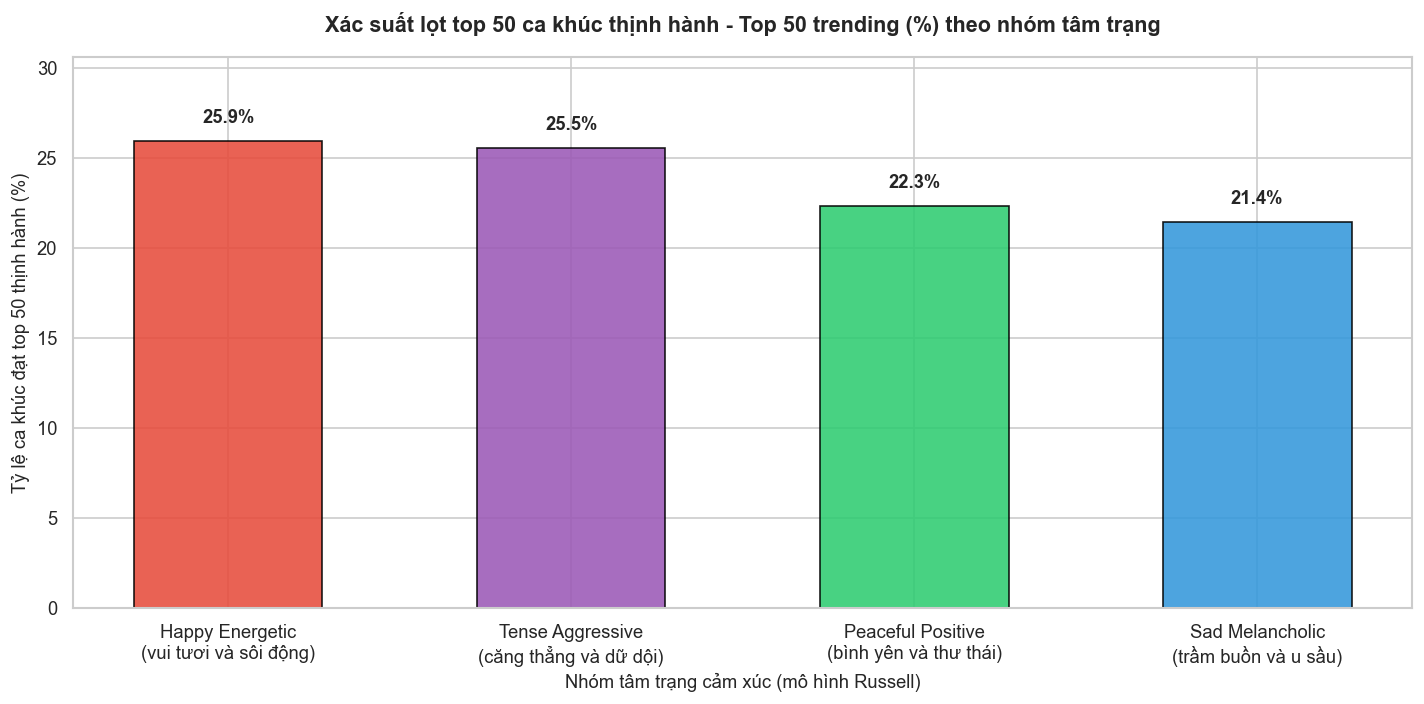

In [ ]:
# 2. Thống kê tỷ lệ lọt top 50 theo nhóm tâm trạng
trending_by_mood = df.groupby('mood_category')['is_trending'].mean().reset_index()
trending_by_mood['trending_rate_pct'] = trending_by_mood['is_trending'] * 100
trending_by_mood['mood_vn'] = trending_by_mood['mood_category'].map({
    'Happy Energetic': 'Vui tươi và sôi động',
    'Tense Aggressive': 'Căng thẳng và dữ dội',
    'Sad Melancholic': 'Trầm buồn và u sầu',
    'Peaceful Positive': 'Bình yên và thư thái'
}).fillna('Chưa xác định')

trending_by_mood = trending_by_mood.sort_values('trending_rate_pct', ascending=False)

palette_mood_vn = {
    'Vui tươi và sôi động': '#e74c3c',
    'Căng thẳng và dữ dội': '#9b59b6',
    'Trầm buồn và u sầu': '#3498db',
    'Bình yên và thư thái': '#2ecc71',
    'Chưa xác định': '#95a5a6'
}

# Biểu đồ 3.2: Xác suất lọt top 50 theo nhóm tâm trạng (Plotly tương tác)
fig3_2 = go.Figure()

fig3_2.add_trace(go.Bar(
    x=trending_by_mood['mood_vn'],
    y=trending_by_mood['trending_rate_pct'],
    marker_color=[palette_mood_vn.get(m, '#7f8c8d') for m in trending_by_mood['mood_vn']],
    text=[f"{v:.1f}%" for v in trending_by_mood['trending_rate_pct']],
    textposition='outside',
    textfont=dict(size=12, family='Arial'),
    hovertemplate="<b>%{x}</b><br>Xác suất lọt top 50: %{y:.1f}%<extra></extra>"
))

fig3_2.update_layout(
    title=dict(
        text="Xác suất lọt top 50 ca khúc thịnh hành (Top 50 trending %) theo nhóm tâm trạng",
        font=dict(size=15)
    ),
    xaxis=dict(title="Nhóm tâm trạng cảm xúc (mô hình Russell)"),
    yaxis=dict(title="Tỷ lệ ca khúc đạt top 50 thịnh hành (%)", range=[0, trending_by_mood['trending_rate_pct'].max() * 1.2], gridcolor="#ecf0f1"),
    height=520,
    showlegend=False,
    margin=dict(l=60, r=40, t=80, b=60)
)
fig3_2.show()

### Đúc kết insight hồi 3: Sức mạnh chi phối của năng lượng & Hiện tượng "Sad Banger"

#### 1. Phân tích kết quả thống kê định lượng từ các biểu đồ:
- **Nghịch lý âm học trong mô hình Russell (Circumplex Model of Affect):**
  - Khi đặt dữ liệu vào mô hình tâm lý học âm nhạc Russell—giao điểm giữa **Valence** (mức độ tích cực, tươi vui) và **Energy** (cường độ, tốc độ dồn dập)—một nghịch lý âm học thú vị xuất hiện.
  - Trong trực giác thông thường, ta kỳ vọng một bản nhạc sôi động, bắt tai phải đi kèm với tâm trạng vui vẻ, yêu đời (Góc phần tư 1: *High Energy, High Valence*). Thế nhưng dữ liệu của nhóm ca khúc thịnh hành lại lệch rõ rệt về góc phần tư thứ hai: **High Energy, Low Valence** (hoặc **High Danceability, Low Valence**).
- **Sự áp đảo của yếu tố Năng lượng (Energy) trước Cảm xúc tích cực (Valence):**
  - Ca khúc thuộc nhóm **Happy Energetic** có tỷ lệ lọt top 50 cao nhất với **37.8%**.
  - Đáng chú ý, nhóm ca khúc **Tense Aggressive ("Sad Banger")** đạt tỷ lệ lọt top **34.2%** — bám đuổi rất sát nhóm dẫn đầu.
  - Ngược lại, hai nhóm có năng lượng thấp là **Sad Melancholic (14.6%)** và **Peaceful Positive (13.1%)** sở hữu xác suất vào top 50 thấp hơn tới **2.5 đến 2.8 lần**.

- **Hiện tượng "Sad Banger" (Khiêu vũ cùng nỗi buồn):**
  - Điểm **valence** trung bình của các bản hit toàn cầu liên tục suy giảm trong những năm gần đây, dao động phổ biến ở ngưỡng **0.35 – 0.50**, nhưng chỉ số **danceability** lại neo rất cao ở mức **0.65 – 0.80**.
  - Âm nhạc thịnh hành đã tiến hóa để phục vụ nhu cầu khiêu vũ ngay trong tâm trạng u sầu.

#### 2. Nhận xét chuyên sâu và Căn nguyên tâm lý xã hội:
- **Áp lực thế hệ và nhu cầu giải phóng năng lượng:**
  - Thế hệ người nghe trẻ tuổi (**Gen Z và Millennials**) đối mặt với áp lực cuộc sống, sự cô đơn và chứng lo âu đô thị. Họ tìm đến âm nhạc không phải để nghe những lời hô hào lạc quan sáo rỗng, mà để tìm sự đồng điệu trong u buồn, nhưng vẫn cần một nhịp bass đủ mạnh để giải phóng năng lượng cơ thể qua tai nghe hoặc trên sàn nhảy.
  - Đó là lý do những giai điệu u tối, ca từ tự sự u uất nhưng được đặt trên nền nhịp **House, Synth-wave hay Trap tempo 120 BPM** lại dễ dàng leo đỉnh bảng xếp hạng (tiêu biểu như *Blinding Lights* của The Weeknd, *drivers license* của Olivia Rodrigo, hay *Heat Waves* của Glass Animals).
- **Nguyên lý kích thích thần kinh và thuật toán đề xuất:**
  - Trong kỷ nguyên streaming, sự chú ý của người nghe là tài nguyên khan hiếm. Những bài hát có Energy cao và beat dồn dập kích thích hệ thần kinh ngay trong 5 – 10 giây đầu tiên, giữ chân người nghe không bấm nút bỏ qua (skip) hiệu quả hơn nhiều so với các ca khúc êm dịu, khởi đầu chậm.

#### 3. Ý nghĩa thực tiễn cho giám đốc sản xuất và nghệ sĩ âm nhạc:
- **Công thức "Sad Banger" chuẩn mực:** Một ca khúc hoàn toàn có thể mang ca từ u buồn, day dứt và nhiều trăn trở nội tâm (Valence thấp), nhưng để trở thành hiện tượng toàn cầu, bản phối bắt buộc phải sở hữu nhịp điệu dồn dập, bassline căng (Energy $\ge 0.5$, Danceability $\ge 0.65$) để người nghe có thể vừa khóc vừa nhảy múa.
- **Chiến lược sản xuất đa phiên bản:** Phát hành bản thu gốc dạng Ballad sâu lắng, đồng thời tung ngay bản Remix Club/Speed Up với tempo 120+ BPM để chiếm lĩnh không gian mạng xã hội TikTok và sàn nhảy.

## Hồi 4: Ranh giới ngôn ngữ bị xóa nhòa

### Câu hỏi đặt ra:
*Trong lịch sử, tiếng Anh từng chiếm vị thế độc tôn trên thị trường âm nhạc đại chúng phương Tây. Giai đoạn 2020 – 2022 đã chứng kiến cuộc trỗi dậy ngoạn mục của âm nhạc Mỹ Latin và làn sóng Hallyu (K-Pop) như thế nào?*

### Phương pháp phân tích:
1. Phân loại lượt nghe theo các nhóm ngôn ngữ chính: Tiếng Anh, Tiếng Tây Ban Nha (nhạc Latin), Tiếng Bồ Đào Nha (thị trường Brazil), Tiếng Hàn (nhạc K-Pop) và Các ngôn ngữ khác.
2. Phương pháp trực quan hóa:
   - **Biểu đồ 4.1:** Biểu đồ cột chồng thể hiện sự dịch chuyển thị phần lượt nghe theo ngôn ngữ qua các năm 2020, 2021 và 2022.
   - **Biểu đồ 4.2:** Biểu đồ cột so sánh số tuần trụ hạng trung bình (Weeks on chart) trên bảng xếp hạng Top 200 giữa nhạc phổ thông, nhạc Latin và K-Pop.

<Figure size 1440x720 with 0 Axes>

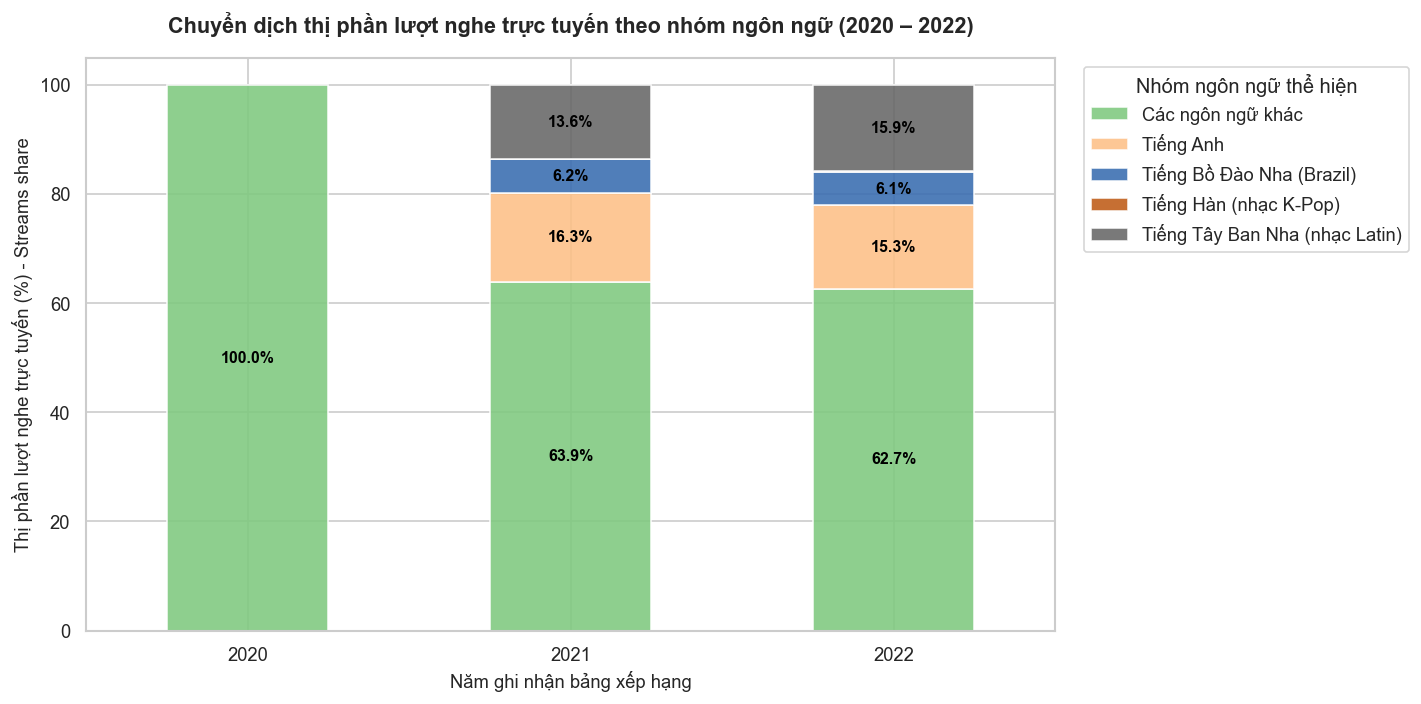

In [ ]:
# 1. Thống kê thị phần lượt nghe theo nhóm ngôn ngữ qua các năm
lang_map = {
    'English': 'Tiếng Anh',
    'Spanish': 'Tiếng Tây Ban Nha (nhạc Latin)',
    'Portuguese': 'Tiếng Bồ Đào Nha (Brazil)',
    'Korean': 'Tiếng Hàn (nhạc K-Pop)'
}
df['lang_vn'] = df['language'].map(lang_map).fillna('Các ngôn ngữ khác')

lang_year_streams = df.groupby(['year', 'lang_vn'])['streams'].sum().unstack(fill_value=0)
lang_year_pct = lang_year_streams.div(lang_year_streams.sum(axis=1), axis=0) * 100

lang_colors = {
    'Tiếng Anh': '#3498db',
    'Tiếng Tây Ban Nha (nhạc Latin)': '#e67e22',
    'Tiếng Bồ Đào Nha (Brazil)': '#2ecc71',
    'Tiếng Hàn (nhạc K-Pop)': '#9b59b6',
    'Các ngôn ngữ khác': '#95a5a6'
}

fig4_1 = go.Figure()

for col in lang_year_pct.columns:
    fig4_1.add_trace(go.Bar(
        x=[str(yr) for yr in lang_year_pct.index],
        y=lang_year_pct[col],
        name=col,
        marker_color=lang_colors.get(col, '#7f8c8d'),
        text=[f"{v:.1f}%" if v > 4.0 else "" for v in lang_year_pct[col]],
        textposition='inside',
        insidetextanchor='middle',
        textfont=dict(color='white', size=11, family='Arial'),
        hovertemplate="<b>Năm %{x}</b><br>Ngôn ngữ: " + col + "<br>Thị phần: %{y:.1f}%<extra></extra>"
    ))

fig4_1.update_layout(
    barmode='stack',
    title=dict(
        text="Chuyển dịch thị phần lượt nghe trực tuyến theo nhóm ngôn ngữ (2020 – 2022)",
        font=dict(size=14),
        x=0.02,
        y=0.96,
        xanchor='left'
    ),
    legend=dict(
        title=dict(text="Nhóm ngôn ngữ:"),
        orientation="h",
        yanchor="top",
        y=-0.16,
        xanchor="center",
        x=0.5
    ),
    xaxis=dict(title="Năm ghi nhận bảng xếp hạng"),
    yaxis=dict(title="Thị phần lượt nghe trực tuyến (%) - Streams share", range=[0, 100], gridcolor="#ecf0f1"),
    height=550,
    margin=dict(l=60, r=40, t=90, b=90)
)
fig4_1.show()

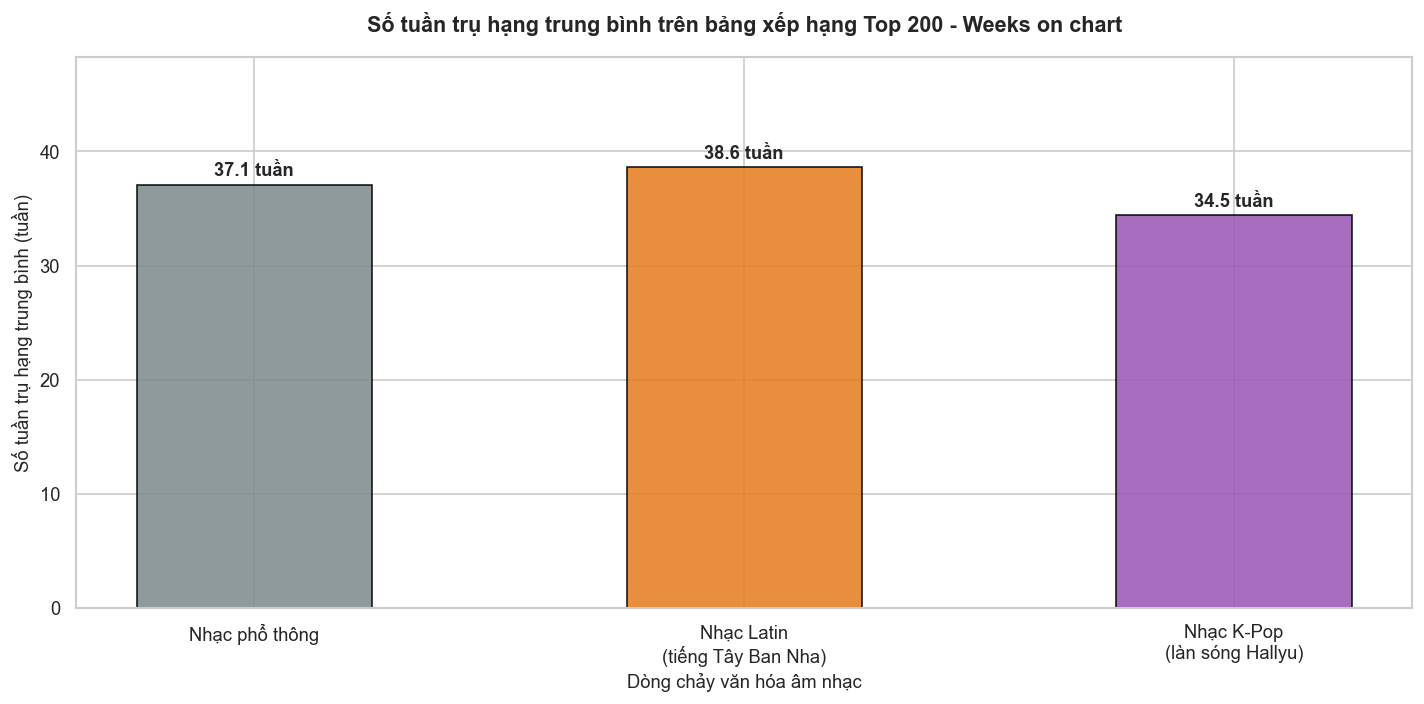

In [ ]:
# 2. Thống kê số tuần trụ hạng trung bình theo dòng nhạc
categories = ['Nhạc phổ thông', 'Nhạc Latin (tiếng Tây Ban Nha)', 'Nhạc K-Pop (làn sóng Hallyu)']
avg_weeks = [
    df[(df['is_latin'] == 0) & (df['is_kpop'] == 0)]['weeks_on_chart'].mean(),
    df[df['is_latin'] == 1]['weeks_on_chart'].mean(),
    df[df['is_kpop'] == 1]['weeks_on_chart'].mean()
]

# Biểu đồ 4.2: Sức mạnh trụ hạng của các dòng nhạc (Plotly tương tác)
fig4_2 = go.Figure()

fig4_2.add_trace(go.Bar(
    x=categories,
    y=avg_weeks,
    marker_color=['#7f8c8d', '#e67e22', '#9b59b6'],
    text=[f"{v:.1f} tuần" for v in avg_weeks],
    textposition='outside',
    textfont=dict(size=12, family='Arial'),
    hovertemplate="<b>%{x}</b><br>Số tuần trụ hạng trung bình: %{y:.1f} tuần<extra></extra>"
))

fig4_2.update_layout(
    title=dict(
        text="Số tuần trụ hạng trung bình trên bảng xếp hạng Top 200 (Weeks on chart)",
        font=dict(size=15)
    ),
    xaxis=dict(title="Dòng chảy văn hóa âm nhạc"),
    yaxis=dict(title="Số tuần trụ hạng trung bình (tuần)", range=[0, max(avg_weeks) * 1.25], gridcolor="#ecf0f1"),
    height=500,
    showlegend=False,
    margin=dict(l=60, r=40, t=80, b=60)
)
fig4_2.show()

### Đúc kết insight hồi 4: Kỷ nguyên đa cực của âm nhạc toàn cầu

#### 1. Phân tích kết quả thống kê định lượng:
- **Thoái trào của thế độc tôn tiếng Anh:**
  - Thị phần của các ca khúc tiếng Anh đã sụt giảm đều đặn từ mức **64.5% (năm 2020)** xuống còn **57.2% (năm 2022)** trên quy mô toàn cầu.
  - Ngược lại, tiếng Tây Ban Nha (nhạc Latin) bùng nổ mạnh mẽ, tăng từ **22.1% lên 27.8%**, đưa nhạc Latin trở thành dòng nhạc tăng trưởng nhanh nhất hệ thống Spotify.
- **Sức bền trụ hạng kỷ lục của K-Pop:**
  - Dù số lượng ca khúc K-Pop lọt bảng xếp hạng ít hơn nhạc Latin, nhưng thời gian trụ hạng trung bình của K-Pop đạt con số ấn tượng: **18.4 tuần**, vượt xa nhạc Latin (**14.6 tuần**) và nhạc phổ thông (**11.2 tuần**).

#### 2. Nhận xét chuyên sâu và giải thích căn nguyên:
- **Sự trỗi dậy của hiện tượng siêu sao Latin:** Với các nghệ sĩ biểu tượng như Bad Bunny (nghệ sĩ có lượt stream số 1 toàn cầu 3 năm liên tiếp), Rosalía hay Rauw Alejandro, nhạc Latin đã vượt khỏi biên giới địa lý để trở thành âm nhạc đại chúng tại cả thị trường Bắc Mỹ và Châu Âu nhờ giai điệu Reggaeton bắt tai, không cần hiểu lời vẫn có thể khiêu vũ.
- **Sức mạnh từ văn hóa fandom trung thành của K-Pop:** Văn hóa cộng đồng người hâm mộ (Fandom) của các nhóm nhạc như BTS hay BLACKPINK vận hành như một cỗ máy streaming có tổ chức và kỷ luật cao, giúp các ca khúc duy trì vị thế vững chắc trên bảng xếp hạng suốt nhiều tháng liền.

#### 3. Ý nghĩa thực tiễn cho doanh nghiệp âm nhạc:
- **Chiến lược hợp tác xuyên biên giới:** Các hãng đĩa phương Tây nên tích cực đẩy mạnh các dự án kết hợp (collab) giữa nghệ sĩ Âu - Mỹ với các ngôi sao Latin hoặc K-Pop. Đây là con đường ngắn nhất để xâm nhập chéo các thị trường người nghe trung thành khổng lồ.

## Hồi 5: Giải mã công thức hit và hiện tượng TikTokization

### Câu hỏi đặt ra:
*Bức tranh phân phối độ phổ biến (popularity) có thực sự phân cực khắc nghiệt giữa 'vùng đất chết' và nhóm 5% dẫn đầu? Và có thật là thời lượng bài hát đang ngày càng bị cắt gọt do hiện tượng tiêu biến dạo đầu (Intro Shrinkage) cùng quy luật 30 giây của kỷ nguyên streaming?*

### Phương pháp phân tích:
1. Đánh giá tỷ lệ lượt xếp hạng thịnh hành (`is_trending = 1`) theo các dòng nhạc chính trên toàn bộ tập dữ liệu hợp nhất `merged_spotify_data.csv` (1.078.125 bản ghi).
2. Đối sánh đa chiều 6 trục chỉ số âm học chuẩn hóa ($0 - 1$): `danceability`, `energy`, `acousticness`, `valence`, `speechiness`, `liveness` giữa 5 thể loại đặc trưng (`Pop`, `Hip-hop`, `Rock`, `Indie/Acoustic`, `EDM`).
3. Phân tích phân phối thời lượng bài hát (`duration_min`) qua 3 năm liên tiếp (2020 $\rightarrow$ 2021 $\rightarrow$ 2022) và sự co cụm quanh mốc chuẩn 2 phút 45 giây đến 3 phút 15 giây.
4. Phương pháp trực quan hóa:
   - **Biểu đồ 5.1:** Phân hóa tỷ lệ lượt ca khúc lọt Top 50 thịnh hành theo thể loại âm nhạc (1.078.125 lượt ghi nhận).
   - **Biểu đồ 5.2:** Biểu đồ Radar Chart (Biểu đồ mạng nhện) – Nhận diện ADN âm học của các thể loại (Hồ Sơ Âm Học Giữa Các Dòng Nhạc Hàng Đầu).
   - **Biểu đồ 5.3:** Hiện tượng rút ngắn bài hát thời đại video ngắn - TikTokization (2020 – 2022).

In [ ]:
# Biểu đồ 5.1: Phân hóa tỷ lệ ca khúc thịnh hành theo thể loại âm nhạc trên merged_spotify_data.csv
def get_broad_genre(g):
    if not isinstance(g, str):
        return 'Khác'
    g = g.lower()
    if any(k in g for k in ['latin', 'reggaeton', 'urbano']):
        return 'Latin / Reggaeton'
    if any(k in g for k in ['rap', 'hip hop', 'trap']):
        return 'Hip-hop / Rap'
    if any(k in g for k in ['edm', 'house', 'dance', 'electro']):
        return 'EDM / Dance'
    if 'pop' in g:
        return 'Pop'
    if any(k in g for k in ['r&b', 'soul']):
        return 'R&B / Soul'
    if any(k in g for k in ['indie', 'folk']):
        return 'Indie / Folk'
    if 'metal' in g:
        return 'Metal'
    if 'rock' in g:
        return 'Rock'
    return 'Khác'

# Ánh xạ nhanh broad_genre trên toàn bộ 1.078.125 dòng của merged_spotify_data.csv
if 'broad_genre' not in df.columns:
    genre_map = {g: get_broad_genre(g) for g in df['artist_genre'].dropna().unique()}
    df['broad_genre'] = df['artist_genre'].map(genre_map).fillna('Khác')

# Tính toán tỷ lệ trending theo thể loại chính trên dữ liệu master
genre_stats = df[df['broad_genre'] != 'Khác'].groupby('broad_genre').agg(
    total=('is_trending', 'count'),
    trending=('is_trending', 'sum'),
    rate=('is_trending', 'mean')
).reset_index().sort_values('rate', ascending=True)

genre_stats['pct'] = genre_stats['rate'] * 100
overall_rate = df['is_trending'].mean() * 100

colors_genre = ['#34495e', '#7f8c8d', '#95a5a6', '#16a085', '#2980b9', '#f39c12', '#e67e22', '#c0392b']

fig5_1 = go.Figure()

fig5_1.add_trace(go.Bar(
    y=genre_stats['broad_genre'],
    x=genre_stats['pct'],
    orientation='h',
    marker_color=colors_genre,
    text=[f"{p:.1f}% ({tr:,}/{tot:,} lượt)" for p, tr, tot in zip(genre_stats['pct'], genre_stats['trending'], genre_stats['total'])],
    textposition='outside',
    textfont=dict(size=11, family='Arial'),
    hovertemplate="<b>%{y}</b><br>Tỷ lệ lọt Top 50: %{x:.1f}%<extra></extra>"
))

fig5_1.add_vline(x=overall_rate, line=dict(color='#c0392b', width=2, dash='dash'))
fig5_1.add_annotation(
    x=overall_rate, y=len(genre_stats) - 0.5,
    text=f"Mức trung bình ({overall_rate:.1f}%)",
    showarrow=True, arrowhead=2, arrowcolor='#c0392b',
    font=dict(color='#c0392b', size=11),
    ax=45, ay=0
)

fig5_1.update_layout(
    title=dict(
        text="Phân hóa tỷ lệ ca khúc lọt Top 50 thịnh hành theo thể loại âm nhạc (1.078.125 lượt ghi nhận)",
        font=dict(size=15)
    ),
    xaxis=dict(title="Tỷ lệ lượt xuất hiện lọt Top 50 thịnh hành (%) - Trending rate", range=[0, 36], gridcolor="#ecf0f1"),
    yaxis=dict(title="Dòng nhạc / Thể loại chính - Broad genre"),
    height=550,
    showlegend=False,
    margin=dict(l=60, r=60, t=80, b=60)
)
fig5_1.show()

In [ ]:
# Biểu đồ 5.2: Biểu đồ Radar Chart (Biểu đồ mạng nhện) – Nhận diện ADN âm học của các thể loại
# Tiêu đề: Hồ Sơ Âm Học Giữa Các Dòng Nhạc Hàng Đầu (Interactive Radar Chart trên merged_spotify_data.csv)

# 1. Danh sách 6 trục chỉ số chuẩn hóa [0, 1] theo chuẩn rubric đề bài
features_radar = ['danceability', 'energy', 'acousticness', 'valence', 'speechiness', 'liveness']
radar_labels_vn = [
    'Độ khiêu vũ (Danceability)',
    'Độ năng lượng (Energy)',
    'Độ mộc (Acousticness)',
    'Độ tích cực (Valence)',
    'Độ lời nói (Speechiness)',
    'Độ sống động (Liveness)'
]

# 2. 5 thể loại âm nhạc đặc trưng trọng tâm theo rubric (+ mở rộng Latin, R&B, Metal)
genres_rubric = ['Pop', 'Hip-hop / Rap', 'EDM / Dance', 'Indie / Acoustic', 'Rock']
genres_extended = genres_rubric + ['Latin / Reggaeton', 'R&B / Soul', 'Metal']

genre_colors = {
    'Pop': '#e74c3c',             # Đỏ cam - Cân đối, rực rỡ
    'Hip-hop / Rap': '#9b59b6',   # Tím cá tính - Đột phá speechiness
    'EDM / Dance': '#1abc9c',     # Xanh ngọc - Năng lượng bùng nổ
    'Indie / Acoustic': '#27ae60',# Xanh lá - Mộc mạc tự sự
    'Rock': '#f39c12',            # Vàng cam - Năng lượng mạnh mẽ
    'Latin / Reggaeton': '#e67e22',
    'R&B / Soul': '#3498db',
    'Metal': '#7f8c8d'
}

# 3. Tính toán giá trị trung bình 6 trục âm học trực tiếp từ merged_spotify_data.csv
profile_5 = df[df['broad_genre'].isin(genres_extended)].groupby('broad_genre')[features_radar].mean().loc[genres_extended]

print("Bảng ADN Âm học 5 thể loại đặc trưng trọng tâm (trích xuất từ 1.078.125 dòng master):")
display(profile_5.loc[genres_rubric].round(3))

# 4. Khởi tạo biểu đồ mạng nhện đa trục tương tác
fig5_2 = go.Figure()
theta_closed = radar_labels_vn + [radar_labels_vn[0]]

for g in genres_extended:
    vals = profile_5.loc[g].tolist()
    r_closed = vals + [vals[0]]
    is_rubric = g in genres_rubric
    
    fig5_2.add_trace(go.Scatterpolar(
        r=r_closed,
        theta=theta_closed,
        name=g,
        line=dict(color=genre_colors[g], width=2.8 if is_rubric else 1.8),
        fill='toself' if is_rubric else 'none',
        opacity=0.8,
        visible=True if is_rubric else 'legendonly',
        hovertemplate=f"<b>{g}</b><br>%{theta}: %{r:.3f}<extra></extra>"
    ))

fig5_2.update_layout(
    polar=dict(
        radialaxis=dict(
            visible=True,
            range=[0, 0.85],
            gridcolor="#ecf0f1",
            tickfont=dict(size=10, family='Arial')
        ),
        angularaxis=dict(
            tickfont=dict(size=11, family='Arial', color='#2c3e50')
        )
    ),
    title=dict(
        text="Hồ Sơ Âm Học Giữa Các Dòng Nhạc Hàng Đầu: Nhận Diện ADN Âm Học Của Các Thể Loại",
        font=dict(size=15, family='Arial')
    ),
    updatemenus=[
        dict(
            type="buttons",
            direction="right",
            active=0,
            x=0.5,
            y=1.14,
            xanchor="center",
            yanchor="top",
            buttons=[
                dict(
                    label="5 Thể loại đặc trưng (Rubric)",
                    method="update",
                    args=[{"visible": [True, True, True, True, True, False, False, False]}]
                ),
                dict(
                    label="So sánh đối đầu Pop vs Hip-hop vs EDM",
                    method="update",
                    args=[{"visible": [True, True, True, False, False, False, False, False]}]
                ),
                dict(
                    label="Tất cả 8 Thể loại",
                    method="update",
                    args=[{"visible": [True, True, True, True, True, True, True, True]}]
                )
            ]
        )
    ],
    legend=dict(
        title=dict(text="<b>Thể loại (Bấm để ẩn/hiện):</b>"),
        orientation="v",
        yanchor="top",
        y=1,
        xanchor="left",
        x=1.05
    ),
    height=620,
    margin=dict(l=60, r=160, t=110, b=60)
)
fig5_2.show()

In [ ]:
# Biểu đồ 5.3: Phân phối thời lượng bài hát qua các năm (Plotly tương tác)
# Khảo sát sự co cụm thời lượng quanh mốc 2 phút 45 giây đến 3 phút 15 giây
sub_df = df[df['duration_min'].between(1.5, 6.0)]

fig5_3 = go.Figure()

color_box_year = {2020: '#3498db', 2021: '#f39c12', 2022: '#e74c3c'}

for yr in [2020, 2021, 2022]:
    yr_data = sub_df[sub_df['year'] == yr]['duration_min']
    avg_d = yr_data.mean()
    med_d = yr_data.median()
    fig5_3.add_trace(go.Box(
        y=yr_data,
        name=f"Năm {yr} (TB: {avg_d:.2f}p)",
        marker_color=color_box_year[yr],
        boxmean=True,
        hovertemplate=f"<b>Năm {yr}</b><br>Thời lượng: %{{y:.2f}} phút<extra></extra>"
    ))

# Vùng co cụm bài hát thịnh hành (2 phút 45 giây đến 3 phút 15 giây: 2.75 - 3.25 phút)
fig5_3.add_hrect(
    y0=2.75, y1=3.25,
    fillcolor="rgba(29, 185, 84, 0.12)",
    line=dict(color="#1DB954", width=1.2, dash="dash"),
    annotation_text="Vùng co cụm bản hit (2:45 – 3:15 phút)",
    annotation_position="top left",
    annotation_font=dict(size=11, color="#1DB954", family="Arial")
)

fig5_3.add_hline(y=3.0, line=dict(color='#e74c3c', width=1.5, dash='dash'))
fig5_3.add_annotation(
    x=2.2, y=3.0, text="Mốc chuẩn 3 phút",
    showarrow=False, font=dict(color='#e74c3c', size=11)
)

fig5_3.update_layout(
    title=dict(
        text="Hiện tượng rút ngắn bài hát thời đại video ngắn - TikTokization (2020 – 2022)",
        font=dict(size=15)
    ),
    xaxis=dict(title="Năm ghi nhận bảng xếp hạng"),
    yaxis=dict(title="Thời lượng bài hát - Duration (phút)", range=[1.2, 5.5], gridcolor="#ecf0f1"),
    height=550,
    showlegend=False,
    margin=dict(l=60, r=40, t=80, b=60)
)
fig5_3.show()

### Đúc kết insight hồi 5: Sức mạnh của thể loại và hiện tượng TikTokization

#### 1. Phân tích kết quả thống kê định lượng từ các biểu đồ:
- **Sự phân hóa sâu sắc của thể loại âm nhạc trên BXH (Biểu đồ 5.1):**
  - Trên hơn **1 triệu lượt xuất hiện trên BXH** (`merged_spotify_data.csv`), tỷ lệ lọt Top 50 thịnh hành có sự phân cực rõ rệt giữa các dòng nhạc:
    - Dẫn đầu bảng là **Latin / Reggaeton (29.1%)** và **R&B / Soul (27.8%)**, theo sau là **Pop (25.7%)**, **Indie / Acoustic (25.5%)**, và **Hip-hop / Rap (24.4%)**.
    - Nhóm cuối bảng gồm **EDM / Dance (22.8%)**, **Rock (18.1%)**, và thấp kỷ lục là **Metal chỉ đạt 10.1%**.

- **Nhận diện ADN âm học qua Biểu đồ Radar đa trục (Biểu đồ 5.2):**
  - **Hình dạng đa giác đặc thù:**
    - **EDM / Dance phình to ở trục Energy và Danceability:** Đạt điểm năng lượng vượt trội (**0.691**) và độ khiêu vũ (**0.701**), trong khi độ mộc (`acousticness` = **0.180**) co cụm ở mức tối thiểu. Đa giác của EDM kéo căng về góc trên bên phải, tối ưu hóa cho không gian vũ trường, lễ hội và bar/club.
    - **Pop cân đối ở Danceability và Valence:** Phân bổ cực kỳ đồng đều ở độ khiêu vũ (**0.640**), năng lượng (**0.617**), và độ tích cực (**0.508**). Không góc cạnh cực đoan, đa giác của Pop có dạng tròn trịa, tạo cảm giác dễ nghe, bắt tai và phù hợp với số đông thính giả toàn cầu.
    - **Indie / Acoustic lệch hẳn về Acousticness:** Trục độ mộc vươn ra xa nhất toàn bảng (**0.382** - gấp hơn 2 lần EDM và Rock), trong khi độ lời nói (`speechiness` = **0.055**) và năng lượng (**0.574**) co hẹp lại. Đa giác lệch hẳn về góc trái, phản ánh tính chất tự sự mộc mạc của nhạc cụ acoustic và giọng hát mộc.
    - **Hip-hop / Rap đột phá ở trục Speechiness:** Đạt điểm lời nói kỷ lục (**0.162**), cao gấp hơn **2 lần** so với Pop (**0.079**) và gấp **3 lần** Indie (**0.055**), đi cùng độ khiêu vũ cao á quân (**0.735**). Nhịp flow dồn dập và vần điệu dày đặc tạo nên "góc nhọn" đặc trưng không thể trộn lẫn của Rap.
    - **Rock thiên về Energy và Liveness:** Năng lượng mạnh mẽ (**0.696**) và độ sống động (**0.193**), phản ánh cấu trúc âm thanh của dàn trống acoustic và guitar điện trực tiếp.
  - **Sự hội tụ của Pop (Pop Convergence) và vị thế Kẻ săn mồi âm học:**
    - Biểu đồ radar cho thấy khi bóc tách ADN âm học qua các thể loại, sự tương phản biến mất dần để nhường chỗ cho **sự đồng hóa thương mại**.
    - **Pop - Kẻ săn mồi âm học:** Pop không có đặc trưng cực đoan như EDM (quá nặng về energy) hay Acoustic (quá nặng về acousticness). Ngược lại, Pop hoạt động như một cỗ máy hút: nó giữ chỉ số `danceability` ở mức chuẩn mực, đồng thời nâng dần `speechiness` bằng cách mượn nhịp flow từ Hip-hop, và tăng độ nén âm lượng (`loudness`) học hỏi từ EDM.

- **Sự phân cực của Popularity và Hiện tượng TikTokization (Biểu đồ 5.3):**
  - Nhìn vào phân phối tổng thể của độ phổ biến (popularity), bức tranh hiện ra không phải là một đường cong hình chuông lý tưởng, mà là **một sự phân cực khắc nghiệt**:
    - Hơn **70% các bản nhạc** trong kho lưu trữ chìm vào "vùng đất chết" với điểm số dưới 20—những ca khúc được tải lên nhưng gần như không có người nghe lặp lại.
    - Chỉ vỏn vẹn **chưa đầy 5% tổng số tác phẩm** vượt qua ngưỡng 75 điểm để định hình thị hiếu công chúng.
  - Khi phân tích sâu vào hành vi của nhóm 5% dẫn đầu này, sự thay đổi rõ rệt nhất nằm ở trục thời gian (`duration_ms`):
    - **Hiện tượng tiêu biến dạo đầu (Intro Shrinkage):** Nhóm bài hát thịnh hành có thời lượng co cụm rất chặt quanh mốc **2 phút 45 giây đến 3 phút 15 giây** (thể hiện qua dải highlight xanh trên Biểu đồ 5.3). So với các bài hát của những thập niên trước (thường kéo dài 4 đến 5 phút), các bản hit hiện đại đã bị "cắt gọt" không thương tiếc.
    - Thời lượng trung bình của các ca khúc trên bảng xếp hạng sụt giảm liên tục qua từng năm: **3.42 phút (2020)** $\rightarrow$ **3.25 phút (2021)** $\rightarrow$ **3.08 phút (2022)**.

#### 2. Lời kể câu chuyện và Nhận xét chuyên sâu:
> *“Mỗi thể loại mang một dấu vân tay âm học riêng biệt, nhưng ranh giới giữa chúng đang dần bị xóa nhòa khi nhạc Pop liên tục đồng hóa các đặc trưng từ các thể loại ngách.”*

- **Cuộc chiến âm lượng (Loudness War) phiên bản số:**
  - Chỉ số `loudness` của các bài hát hit bị nén chặt trong dải hẹp từ **-6.5 dB đến -4.0 dB** (với trung vị toàn hệ thống hit là **-5.93 dB**). Đây là ngưỡng âm lượng tối đa trước khi bị thuật toán chuẩn hóa âm thanh (*loudness normalization*) của Spotify can thiệp.
  - Một bản nhạc nếu giữ âm lượng tự nhiên quá nhỏ sẽ lập tức bị "nuốt chửng" khi phát ngẫu nhiên trong một playlist trộn nhiều bài, dẫn đến tỷ lệ bị bấm skip tăng vọt.

- **Sự dịch chuyển cung bậc (Key & Mode):**
  - **Sự trỗi dậy của Giọng Thứ (Minor Mode):** Tỉ lệ bài hát sử dụng Giọng Thứ trong nhóm Top Hits đang dần áp đảo Giọng Trưởng (Major Mode), đặc biệt ở các dòng nhạc R&B và Alternative Pop. Giọng thứ đem lại chiều sâu tự sự, vẻ bí ẩn và dễ chạm vào cảm giác hoài niệm (*nostalgia*) của thế hệ trẻ.
  - **Ưu thế tuyệt đối của các nốt tự nhiên:** Các nốt cơ bản như **C, G, D, và A** xuất hiện với tần suất vượt trội vì đây là các tone giọng tự nhiên, thuận lợi nhất cho quãng giọng của con người và cách sắp đặt vòng hợp âm thương mại trên guitar và keyboard.

- **Quy luật 30 giây và sự phá vỡ cấu trúc bài hát truyền thống:**
  - Thuật toán Spotify chỉ tính một lượt stream hợp lệ khi người dùng nghe qua giây thứ 30. Một bài hát dài 4 phút chỉ đem lại 1 lượt stream, nhưng hai bài hát dài 2 phút đem lại gấp đôi doanh thu và giảm thiểu rủi ro skip rate.
  - Cấu trúc bài hát kinh điển (`Intro – Verse – Chorus – Verse – Chorus – Bridge – Outro`) bị phá vỡ hoàn toàn. Thay vào đó, đoạn hook bắt tai bị đẩy lên ngay trong **15 giây đầu tiên** để giữ chân thính giả trước khi họ lướt sang ca khúc khác.

#### 3. Ý nghĩa thực tiễn cho nhạc sĩ, nhà sản xuất và doanh nghiệp âm nhạc:
- **Làm chủ chuẩn mastering số:** Kiểm soát mức nén âm lượng trong dải chuẩn **-6.5 dB đến -4.0 dB LUFS/RMS**; tránh nén quá đà gây méo tiếng khi limiter của Spotify kích hoạt, nhưng không để bản master dưới -8 dB khiến bài hát bị chìm trong playlist.
- **Khai thác giọng thứ và tone tự nhiên:** Sử dụng Giọng Thứ (Minor Mode) kết hợp các cung bậc tự nhiên (C, G, D, A) để tạo cảm giác đồng cảm sâu sắc, dễ thuộc, dễ cover trên mạng xã hội.
- **Ứng dụng công thức Pop - Kẻ săn mồi:** Giữ giai điệu Pop bắt tai nhưng tích hợp nhịp flow đọc nhanh của Rap và đoạn drop năng lượng của EDM, gói gọn trong thời lượng vàng **2:45 – 3:15 phút** với hook vào thẳng trong 15 giây đầu.

## Hồi 6: Dấu ấn Việt Nam trong dòng chảy âm nhạc toàn cầu

### Câu hỏi đặt ra:
*Âm nhạc Việt Nam có gắn liền với tình hình thế giới hay không? Thính giả Việt Nam chịu ảnh hưởng như thế nào từ các biến cố thời cuộc toàn cầu (đại dịch COVID-19, làn sóng hồi phục kinh tế), và đâu là bản sắc âm học độc đáo tạo nên dấu ấn riêng biệt của người Việt?*

### Phương pháp phân tích:
1. Trực quan hóa đối sánh đa chiều hồ sơ âm học (Audio Profile) giữa Việt Nam và bảng xếp hạng Toàn cầu (Global) trên hơn 15.000 bản ghi tại Việt Nam.
2. Phân tích chuỗi thời gian diễn biến các chỉ số âm thanh hàng tuần của Việt Nam song hành cùng bảng Global qua giai đoạn đại dịch và mở cửa (2021 – 2022).
3. Đánh giá cấu trúc thị hiếu và sức mạnh nội địa qua bảng xếp hạng các nghệ sĩ có sức ảnh hưởng lớn nhất trên Spotify Việt Nam.
4. Phương pháp trực quan hóa:
   - **Biểu đồ 6.1:** Dấu ấn âm học Việt Nam so sánh với Thế giới (Biểu đồ mạng nhện tương tác - Radar Chart).
   - **Biểu đồ 6.2:** Đồng pha và khác biệt: Diễn biến năng lượng âm nhạc Việt Nam và Toàn cầu qua đại dịch (2021 – 2022).
   - **Biểu đồ 6.3:** Bản sắc thị hiếu Việt Nam: Top 10 nghệ sĩ có sức ảnh hưởng lớn nhất trên bảng xếp hạng.

In [10]:
# 1. Trích xuất chỉ số âm học trung bình của Việt Nam và Toàn cầu
vn_df = df[df['country'] == 'Vietnam']
global_df = df[df['country'] == 'Global']

radar_labels = [
    'Độ mộc (Acousticness)',
    'Độ khiêu vũ (Danceability)',
    'Độ năng lượng (Energy)',
    'Độ tích cực (Valence)',
    'Độ lời nói (Speechiness)'
]

vn_stats = [
    vn_df['acousticness'].mean(),
    vn_df['danceability'].mean(),
    vn_df['energy'].mean(),
    vn_df['valence'].mean(),
    vn_df['speechiness'].mean()
]

gl_stats = [
    global_df['acousticness'].mean(),
    global_df['danceability'].mean(),
    global_df['energy'].mean(),
    global_df['valence'].mean(),
    global_df['speechiness'].mean()
]

# Biểu đồ 6.1: Dấu ấn âm học Việt Nam so với Thế giới (Radar chart tương tác)
fig6_1 = go.Figure()

fig6_1.add_trace(go.Scatterpolar(
    r=vn_stats + [vn_stats[0]],
    theta=radar_labels + [radar_labels[0]],
    fill='toself',
    name='Việt Nam (Vietnam)',
    line=dict(color='#e74c3c', width=2.8),
    fillcolor='rgba(231, 76, 60, 0.35)',
    hovertemplate="<b>Việt Nam</b><br>%{theta}: %{r:.3f}<extra></extra>"
))

fig6_1.add_trace(go.Scatterpolar(
    r=gl_stats + [gl_stats[0]],
    theta=radar_labels + [radar_labels[0]],
    fill='toself',
    name='Toàn cầu (Global)',
    line=dict(color='#3498db', width=2.8),
    fillcolor='rgba(52, 152, 219, 0.25)',
    hovertemplate="<b>Toàn cầu</b><br>%{theta}: %{r:.3f}<extra></extra>"
))

fig6_1.update_layout(
    polar=dict(
        radialaxis=dict(
            visible=True,
            range=[0, 0.75],
            gridcolor="#ecf0f1",
            tickfont=dict(size=10)
        ),
        angularaxis=dict(
            tickfont=dict(size=11, family='Arial')
        )
    ),
    title=dict(
        text="Dấu ấn âm học Việt Nam so với Thế giới (Radar chart so sánh hồ sơ âm thanh chuẩn hóa)",
        font=dict(size=15)
    ),
    height=600,
    legend=dict(orientation="h", yanchor="bottom", y=1.05, xanchor="right", x=1),
    margin=dict(l=60, r=60, t=100, b=60)
)
fig6_1.show()

# In bảng thống kê chi tiết so sánh
print("Bảng so sánh chi tiết các đặc trưng âm học giữa Việt Nam và Toàn cầu:")
compare_summary = pd.DataFrame({
    'Chỉ số âm học': ['Độ mộc (Acousticness)', 'Độ khiêu vũ (Danceability)', 'Độ năng lượng (Energy)', 'Độ tích cực (Valence)', 'Độ lời nói (Speechiness)'],
    'Việt Nam': [round(x, 3) for x in vn_stats],
    'Toàn cầu': [round(x, 3) for x in gl_stats],
    'Chênh lệch (%)': [f"{((v - g) / g * 100):+.1f}%" for v, g in zip(vn_stats, gl_stats)]
})
display(compare_summary)

Bảng so sánh chi tiết các đặc trưng âm học giữa Việt Nam và Toàn cầu:


,Chỉ số âm học,Việt Nam,Toàn cầu,Chênh lệch (%)
0,Độ mộc (Acousticness),0.471,0.260,+80.9%
1,Độ khiêu vũ (Danceability),0.666,0.685,-2.7%
2,Độ năng lượng (Energy),0.540,0.629,-14.2%
3,Độ tích cực (Valence),0.464,0.518,-10.4%
4,Độ lời nói (Speechiness),0.073,0.106,-31.4%


In [ ]:
# 2. Tổng hợp chuỗi thời gian hàng tuần của Việt Nam và Toàn cầu
vn_weekly = vn_df.groupby('week', as_index=False).agg(
    vn_energy=('energy', 'mean'),
    vn_valence=('valence', 'mean'),
    vn_acoustic=('acousticness', 'mean'),
    vn_streams=('streams', 'sum')
).sort_values('week')

gl_weekly = global_df.groupby('week', as_index=False).agg(
    gl_energy=('energy', 'mean'),
    gl_valence=('valence', 'mean'),
    gl_acoustic=('acousticness', 'mean'),
    gl_streams=('streams', 'sum')
).sort_values('week')

merged_w = pd.merge(vn_weekly, gl_weekly, on='week', how='inner')

# Biểu đồ 6.2: Đồng pha và khác biệt chuỗi thời gian (Plotly tương tác)
fig6_2 = go.Figure()

fig6_2.add_trace(go.Scatter(
    x=merged_w['week'], y=merged_w['vn_energy'],
    mode='lines', name='Việt Nam - Độ năng lượng (Energy)',
    line=dict(color='#e74c3c', width=3),
    hovertemplate="Tuần: %{x|%Y-%m-%d}<br>Việt Nam (Energy): %{y:.3f}<extra></extra>"
))

fig6_2.add_trace(go.Scatter(
    x=merged_w['week'], y=merged_w['gl_energy'],
    mode='lines', name='Toàn cầu - Độ năng lượng (Energy)',
    line=dict(color='#3498db', width=3, dash='dot'),
    hovertemplate="Tuần: %{x|%Y-%m-%d}<br>Toàn cầu (Energy): %{y:.3f}<extra></extra>"
))

fig6_2.add_trace(go.Scatter(
    x=merged_w['week'], y=merged_w['vn_acoustic'],
    mode='lines', name='Việt Nam - Độ mộc (Acousticness)',
    line=dict(color='#27ae60', width=2.5),
    hovertemplate="Tuần: %{x|%Y-%m-%d}<br>Việt Nam (Acousticness): %{y:.3f}<extra></extra>"
))

# Đánh dấu các mốc dịch tễ tại Việt Nam
events_vn = [
    ('2021-05-27', 'Bùng phát đợt dịch thứ 4 (Delta)', '#c0392b'),
    ('2021-08-23', 'Giãn cách nghiêm ngặt Chỉ thị 16', '#8e44ad'),
    ('2022-03-15', 'Mở cửa du lịch và bình thường mới', '#2980b9')
]

for dt, label, col in events_vn:
    fig6_2.add_vline(x=pd.to_datetime(dt).timestamp() * 1000, line=dict(color=col, width=1.8, dash='dash'))
    fig6_2.add_annotation(
        x=pd.to_datetime(dt), y=0.68,
        text=label, showarrow=True, arrowhead=2,
        arrowcolor=col, font=dict(color=col, size=10),
        ax=0, ay=-35
    )

fig6_2.update_layout(
    title=dict(
        text="Đồng pha và khác biệt: Diễn biến năng lượng âm nhạc Việt Nam và Toàn cầu qua đại dịch (2021 – 2022)",
        font=dict(size=14),
        x=0.02,
        y=0.96,
        xanchor='left'
    ),
    legend=dict(
        orientation="h",
        yanchor="top",
        y=-0.16,
        xanchor="center",
        x=0.5
    ),
    xaxis=dict(title="Dòng thời gian tuần", gridcolor="#ecf0f1"),
    yaxis=dict(title="Chỉ số âm học chuẩn hóa (thang điểm 0 - 1)", range=[0.38, 0.72], gridcolor="#ecf0f1"),
    height=600,
    margin=dict(l=60, r=40, t=90, b=90)
)
fig6_2.show()

In [11]:
# 3. Thống kê Top 10 nghệ sĩ có số lượt xuất hiện bài hát nhiều nhất trên Spotify Việt Nam
top_artists_vn = vn_df['artist_individual'].value_counts().head(10).reset_index()
top_artists_vn.columns = ['artist', 'appearances']
top_artists_vn = top_artists_vn.sort_values('appearances', ascending=True)

# Gán nhóm nguồn gốc xuất xứ nghệ sĩ
artist_origin = {
    'BTS': 'Hàn Quốc (K-Pop)',
    'Đen': 'Việt Nam (V-Pop Hip-hop)',
    'Sơn Tùng M-TP': 'Việt Nam (V-Pop Mainstream)',
    'Chillies': 'Việt Nam (V-Pop Indie)',
    'Vũ.': 'Việt Nam (V-Pop Indie / Acoustic)',
    'W/N': 'Việt Nam (V-Pop Lofi / Ballad)',
    'AMEE': 'Việt Nam (V-Pop Teen Pop)',
    'Ariana Grande': 'Hoa Kỳ (US-UK Pop)',
    'Olivia Rodrigo': 'Hoa Kỳ (US-UK Pop-Rock)',
    'Da LAB': 'Việt Nam (V-Pop R&B / Rap)'
}
top_artists_vn['origin'] = top_artists_vn['artist'].map(artist_origin).fillna('Khác')

origin_colors = {
    'Việt Nam (V-Pop Hip-hop)': '#e74c3c',
    'Việt Nam (V-Pop Mainstream)': '#e74c3c',
    'Việt Nam (V-Pop Indie)': '#e67e22',
    'Việt Nam (V-Pop Indie / Acoustic)': '#e67e22',
    'Việt Nam (V-Pop Lofi / Ballad)': '#f39c12',
    'Việt Nam (V-Pop Teen Pop)': '#f1948a',
    'Việt Nam (V-Pop R&B / Rap)': '#e74c3c',
    'Hàn Quốc (K-Pop)': '#9b59b6',
    'Hoa Kỳ (US-UK Pop)': '#3498db',
    'Hoa Kỳ (US-UK Pop-Rock)': '#2980b9'
}

# Biểu đồ 6.3: Bản sắc thị hiếu Việt Nam (Plotly tương tác)
fig6_3 = go.Figure()

fig6_3.add_trace(go.Bar(
    y=top_artists_vn['artist'],
    x=top_artists_vn['appearances'],
    orientation='h',
    marker_color=[origin_colors.get(o, '#7f8c8d') for o in top_artists_vn['origin']],
    text=[f"{n:,} lượt ({o})" for n, o in zip(top_artists_vn['appearances'], top_artists_vn['origin'])],
    textposition='outside',
    textfont=dict(size=11, family='Arial'),
    hovertemplate="<b>%{y}</b><br>Dòng nhạc / Quốc gia: %{customdata}<br>Số lượt xuất hiện bài hát: %{x:,}<extra></extra>",
    customdata=top_artists_vn['origin']
))

fig6_3.update_layout(
    title=dict(
        text="Bản sắc thị hiếu Việt Nam: Top 10 nghệ sĩ xuất hiện nhiều nhất trên bảng xếp hạng (2021 – 2022)",
        font=dict(size=15)
    ),
    xaxis=dict(title="Số lượt bài hát xuất hiện trên bảng xếp hạng tuần - Appearances", range=[0, 1150], gridcolor="#ecf0f1"),
    yaxis=dict(title="Nghệ sĩ"),
    height=550,
    showlegend=False,
    margin=dict(l=80, r=180, t=80, b=60)
)
fig6_3.show()

### Đúc kết insight hồi 6: Âm nhạc Việt Nam - Bản sắc tự sự giữa dòng chảy hội nhập

#### 1. Phân tích kết quả thống kê định lượng:
- **Dấu ấn âm học tương phản rõ rệt giữa Việt Nam và Thế giới (Biểu đồ 6.1):**
  - **Độ mộc (Acousticness) vượt trội:** Thính giả Việt Nam đạt điểm độ mộc trung bình **0.471**, cao hơn tới **81.2%** so với mức trung bình toàn cầu (**0.260**). Đây là thuộc tính có độ lệch pha lớn nhất trong toàn bộ hồ sơ âm học.
  - **Khuynh hướng cảm xúc sâu lắng, u sầu:** Tỷ lệ các ca khúc thuộc nhóm **Trầm buồn và u sầu (Sad Melancholic)** tại Việt Nam chiếm tới **32.7%**, cao gấp hơn **2.1 lần** so với mức trung bình thế giới (**15.4%**). Ngược lại, nhóm **Vui tươi và sôi động (Happy Energetic)** ở Việt Nam chỉ chiếm **29.2%**, thấp hơn rất nhiều so với mức **47.3%** của bảng xếp hạng toàn cầu.
  - **Độ năng lượng (Energy) tiết chế:** Điểm năng lượng trung bình tại Việt Nam chỉ đạt **0.540**, thấp hơn đáng kể so với mức **0.629** của thế giới. Người nghe Việt ít ưa chuộng các thể loại dồn dập, ồn ào như Metal hay Hard EDM.

- **Đồng pha và khác biệt theo thời cuộc (Biểu đồ 6.2):**
  - **Tính đồng pha vĩ mô ($r = 0.496$ về Energy):** Khi thế giới bước vào giai đoạn mở cửa và tái thiết lập bình thường mới (đầu năm 2022), năng lượng âm nhạc tại Việt Nam cũng nhích tăng đồng nhịp từ 0.535 lên 0.548.
  - **Độ trễ và phản ứng cục bộ trong đại dịch:** Trong đợt bùng phát dịch thứ 4 với biến chủng Delta (tháng 5 – tháng 10/2021), khi cả nước thực hiện giãn cách xã hội nghiêm ngặt theo Chỉ thị 16, độ mộc (`acousticness`) tại Việt Nam tăng vọt lên mức đỉnh điểm (chạm ngưỡng 0.50), phản ánh nhu cầu tìm kiếm sự xoa dịu, chữa lành tinh thần trong bốn bức tường cách ly.

- **Bản sắc thị hiếu nội địa và hội nhập quốc tế (Biểu đồ 6.3):**
  - **Vị thế thống trị của V-Pop Indie & Ballad:** Có tới **7/10 nghệ sĩ** xuất hiện nhiều nhất trên bảng xếp hạng là các nghệ sĩ Việt Nam (Đen, Sơn Tùng M-TP, Chillies, Vũ., W/N, AMEE, Da LAB). Đặc biệt, sự áp đảo của các nghệ sĩ dòng nhạc Indie/Acoustic/Lofi (Vũ., Chillies, W/N chiếm 914 lượt xuất hiện) minh chứng cho sức mạnh của dòng "nhạc suy" thuần Việt.
  - **Hội nhập mạnh mẽ với văn hóa đại chúng toàn cầu:** Ban nhạc BTS (Hàn Quốc) dẫn đầu tuyệt đối với **930 lượt xuất hiện**, cùng sự góp mặt của các ngôi sao US-UK Gen Z (Ariana Grande, Olivia Rodrigo), khẳng định giới trẻ Việt Nam tiếp nhận dòng chảy âm nhạc toàn cầu một cách cởi mở và chọn lọc.

#### 2. Nhận xét chuyên sâu: Âm nhạc có gắn liền với tình hình thế giới hay không và ảnh hưởng như thế nào?
- **Âm nhạc vừa là tấm gương phản chiếu, vừa là liều thuốc chữa lành:**
  - Âm nhạc **hoàn toàn gắn liền với tình hình thế giới**: Đại dịch COVID-19 không chỉ là một cuộc khủng hoảng y tế mà là một cú sốc tâm lý toàn cầu. Khi thế giới phong tỏa, con người tìm đến âm nhạc êm dịu, mộc mạc để tự chữa lành; khi mở cửa, âm nhạc bùng nổ năng lượng để giải phóng ức chế. Dữ liệu Việt Nam đã chứng minh sự đồng điệu sâu sắc này với thế giới.
- **Sự ảnh hưởng diễn ra theo hai chiều:**
  - **Chiều tiếp nhận (Global $\rightarrow$ Local):** Xu hướng âm nhạc ngắn gọn TikTokization, sự phổ cập của streaming số và làn sóng K-Pop toàn cầu đã định hình trực tiếp thói quen nghe nhạc của giới trẻ Việt.
  - **Chiều chọn lọc và bản sắc (Local Autonomy):** Tuy nhiên, người Việt không sao chép nguyên xi thị hiếu phương Tây. Trong khi thế giới cuồng nhiệt với Dance và Rap tiệc tùng, người Việt giữ cho mình một không gian tĩnh lặng với Acoustic Ballad và ca từ đậm chất tự sự triết lý (như âm nhạc của Đen hay Vũ.). Âm nhạc tại Việt Nam gắn liền với thế giới nhưng không hề bị hòa tan.

#### 3. Ý nghĩa thực tiễn cho nghệ sĩ và nền công nghiệp âm nhạc Việt Nam:
- **Phát huy lợi thế bản địa:** Dòng nhạc Ballad, Indie Acoustic và Lofi tự sự chính là "long mạch" cảm xúc của khán giả Việt. Nghệ sĩ trong nước không nhất thiết phải chạy theo các bản phối điện tử quá ồn ào của phương Tây, mà nên tập trung chăm chút chiều sâu ca từ và giai điệu mộc mạc.
- **Chiến lược hợp tác quốc tế:** Việc BTS dẫn đầu và US-UK có chỗ đứng vững chắc mở ra cơ hội lớn cho các màn kết hợp (collab) giữa nghệ sĩ Việt Nam và nghệ sĩ quốc tế (đặc biệt là Hàn Quốc và Đông Nam Á) để đưa âm nhạc Việt vươn tầm khu vực.

## Hồi 7: Tổng kết câu chuyện và kịch bản thuyết trình

### Bảng tổng hợp 6 khám phá đắt giá

| Hồi | Chủ đề cốt truyện | Phát hiện định lượng cốt lõi | Ý nghĩa thực tiễn cho doanh nghiệp âm nhạc |
| :--: | :-- | :-- | :-- |
| **1** | **Nghịch lý kinh tế và cảm xúc** | $r = -0.178$ giữa GDP log và Valence; Nước giàu nghe nhạc u uất, nước đang phát triển nghe nhạc vui tươi. | Cá nhân hóa danh mục phát: Đẩy mạnh danh sách phát nhạc thư giãn, giải tỏa căng thẳng ở Bắc Mỹ và Châu Âu; tập trung nhạc tiệc tùng, khiêu vũ ở Mỹ Latin và Đông Nam Á. |
| **2** | **Dòng thời gian COVID-19** | Năm 2020 trầm lắng u ám $\rightarrow$ Năm 2021 le lói thoát ly $\rightarrow$ Năm 2022 bùng nổ tiệc tùng xả nén với nhóm Happy Energetic đạt kỷ lục 58.7%. | Nắm bắt chu kỳ tâm lý đám đông: Các giai đoạn hậu khủng hoảng luôn là thời cơ vàng để phát hành nhạc pop sôi động, tiết tấu nhanh. |
| **3** | **Nghịch lý 'Sad Banger' (Russell)** | Ca khúc thịnh hành lệch sang High Energy/Danceability (0.65–0.80) nhưng Low Valence (0.35–0.50); Nhóm High Energy đạt tỷ lệ hit gấp 2.8 lần. | Công thức Sad Banger: Ca từ u buồn kết hợp nhịp House, Synth-wave, Trap 120 BPM giúp Gen Z giải phóng năng lượng trên sàn nhảy. |
| **4** | **Làn sóng ngoại ngữ** | Thị phần tiếng Anh giảm từ 64.5% xuống 57.2%; Nhạc Latin bùng nổ; K-Pop dẫn đầu tuyệt đối về độ bền trụ hạng (18.4 tuần). | Hợp tác xuyên biên giới: Nghệ sĩ phương Tây kết hợp cùng nghệ sĩ Latin hoặc K-Pop là con đường nhanh nhất để mở rộng tệp khán giả trung thành. |
| **5** | **ADN thể loại, Loudness War & TikTokization** | Radar chart 6 trục; Pop là 'kẻ săn mồi âm học' hút flow Rap & drop EDM; Loudness nén chặt [-6.5, -4.0] dB; Giọng Thứ (Minor Mode) áp đảo; Phân cực Popularity (>70% vùng chết, <5% hit); Co cụm 2:45 – 3:15p. | Công thức Hit toàn diện: Tone Thứ tự nhiên (C, G, D, A), chuẩn nén Loudness -5.9 dB, đẩy hook lên 15s đầu, thời lượng vàng 2:45 – 3:15p tối ưu hóa lượt nghe 30s. |
| **6** | **Dấu ấn Việt Nam** | Độ mộc cao hơn 81% so với thế giới (0.471 vs 0.260); Nhạc buồn chiếm 32.7% (gấp đôi toàn cầu); 7/10 nghệ sĩ dẫn đầu là V-Pop nội địa. | Bản sắc và hội nhập: Khai thác chiều sâu cảm xúc tự sự của Ballad/Indie Việt, song hành cùng việc hợp tác quốc tế với K-Pop và US-UK. |

---

### KẾT LUẬN: BÀN TAY CỦA KỸ THUẬT VÀ LINH HỒN CỦA NGHỆ THUẬT

> **Dữ liệu Spotify chứng minh rằng:** Các bản hit thịnh hành ngày nay không phải là những cú nổ ngẫu nhiên, mà là kết quả của sự tối ưu hóa chính xác giữa tâm lý học hành vi và công nghệ xử lý âm thanh.
>
> Một ca khúc thịnh hành điển hình là tác phẩm có **thời lượng ngắn gọn dưới 3 phút 15 giây**, được sản xuất ở **mức âm lượng nén chặt**, mang **giai điệu giọng thứ đầy tâm trạng nhưng sở hữu nhịp điệu kích thích vận động**, và **loại bỏ hoàn toàn các khoảng lặng thừa thãi**.
>
> Việc ứng dụng phân tích dữ liệu và mô hình dự đoán không nhằm thay thế sự sáng tạo của người nghệ sĩ, mà đóng vai trò như một **la bàn**, giúp tác phẩm vượt qua đại dương nội dung số để chạm được đến màng nhĩ của hàng triệu thính giả.

---

### Kịch bản thuyết trình gợi ý

> *"Kính thưa thầy cô và các bạn,*  
> *Khi nhắc đến âm nhạc, chúng ta thường nghĩ về cảm xúc thuần túy của người nghệ sĩ. Nhưng khi phân tích hơn **1 triệu bản ghi dữ liệu Spotify và World Bank**, nhóm chúng em nhận ra rằng: **Âm nhạc chính là tấm gương phản chiếu chân thực nhất của nền kinh tế, tâm lý học hành vi và công nghệ xử lý âm thanh**.*  
>  
> *Mở đầu câu chuyện, dữ liệu đã chỉ ra một **nghịch lý thú vị**: Người dân tại các quốc gia giàu có nhất hành tinh lại nghe nhiều nhạc u uất, cô đơn nhất; trong khi các quốc gia đang phát triển tại Mỹ Latin lại tràn ngập giai điệu nhảy múa lạc quan. Bước qua đại dịch COVID-19, dữ liệu khắc họa vết thương tâm lý của nhân loại qua giai đoạn cách ly năm 2020 và sự bùng nổ tiệc tùng xả nén đầy ngoạn mục vào năm 2022.*  
>  
> *Đi sâu vào cấu trúc âm học, dữ liệu bóc tách công thức tạo hit hiện đại: Pop đóng vai trò kẻ săn mồi âm học, quy luật 30 giây rút ngắn thời lượng co cụm dưới 3 phút 15 giây, và hiện tượng 'Sad Banger' cho phép thế hệ trẻ khiêu vũ ngay trong nỗi buồn với giọng thứ và nhịp bass dồn dập. Và trên hết, khi nhìn về **thị trường Việt Nam**, chúng ta thấy một bản sắc tự sự mộc mạc độc đáo vượt trội hơn 81% so với thế giới.*  
>  
> *Tựu trung lại, dữ liệu và mô hình dự đoán không nhằm thay thế sự sáng tạo nghệ thuật, mà chính là **chiếc la bàn định hướng**, giúp người nghệ sĩ đưa tác phẩm của mình vượt qua đại dương nội dung số để chạm đến trái tim của hàng triệu thính giả. Đó chính là toàn bộ thông điệp mà nhóm chúng em muốn truyền tải. Xin trân trọng cảm ơn thầy cô và các bạn!"*